# 🚴 QuickBite Delivery Services – Round 2: EDA & Feature Engineering

**Organization:** QuickBite Delivery Services  
**Sector:** Food Delivery  
**Objective:** Understand delivery delays and poor performance by analysing order, rider, route, and weather data.

---

## 📋 Table of Contents
1. [Setup & Imports](#1)
2. [Load Datasets](#2)
3. [Data Quality Assessment](#3)
4. [Data Cleaning](#4)
5. [Merge & Combine](#5)
6. [Descriptive Analysis](#6)
7. [Key Visualizations](#7)
8. [Use-Case Analytical Questions](#8)
9. [Feature Engineering](#9)
10. [Encoding Categorical Variables](#10)
11. [Feature Selection](#11)
12. [Summary & Insights](#12)

## 1. Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
from scipy import stats
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.2f}'.format)

PALETTE = ['#E63946','#457B9D','#2A9D8F','#E9C46A','#F4A261','#264653','#A8DADC','#1D3557']
plt.rcParams.update({
    'figure.facecolor' : '#0F1117',
    'axes.facecolor'   : '#1A1D27',
    'axes.edgecolor'   : '#2E3250',
    'axes.labelcolor'  : '#C8D0E7',
    'xtick.color'      : '#8892B0',
    'ytick.color'      : '#8892B0',
    'text.color'       : '#CDD6F4',
    'grid.color'       : '#2E3250',
    'grid.linestyle'   : '--',
    'grid.alpha'       : 0.5,
    'axes.titlesize'   : 14,
    'axes.titleweight' : 'bold',
    'axes.titlepad'    : 12,
    'axes.titlecolor'  : '#CDD6F4',
    'font.family'      : 'DejaVu Sans',
    'figure.dpi'       : 130,
})

def savefig(name):
    plt.savefig(f'{name}.png', dpi=150, bbox_inches='tight',
                facecolor=plt.rcParams['figure.facecolor'])
    plt.show()

print('Libraries loaded.')
print(f'Pandas: {pd.__version__}  |  NumPy: {np.__version__}  |  Seaborn: {sns.__version__}')

Libraries loaded.
Pandas: 3.0.1  |  NumPy: 2.2.1  |  Seaborn: 0.13.2


## 2. Load Datasets

In [2]:
orders   = pd.read_csv('orders.csv',   parse_dates=['order_time'])
riders   = pd.read_csv('riders.csv')
routes   = pd.read_csv('routes.csv')
weather  = pd.read_csv('weather.csv',  parse_dates=['datetime'])
delivery = pd.read_csv('delivery.csv', parse_dates=['pickup_time', 'delivered_time'])

datasets = {'orders': orders, 'riders': riders, 'routes': routes,
            'weather': weather, 'delivery': delivery}

for name, df in datasets.items():
    print(f'{name.upper()}: {df.shape[0]} rows x {df.shape[1]} cols | Columns: {list(df.columns)}')

ORDERS: 1200 rows x 5 cols | Columns: ['order_id', 'order_time', 'restaurant', 'customer_zone', 'order_value_inr']
RIDERS: 80 rows x 5 cols | Columns: ['rider_id', 'experience_level', 'experience_years', 'shift', 'avg_rating']
ROUTES: 1200 rows x 4 cols | Columns: ['route_id', 'zone', 'distance_km', 'traffic_level']
WEATHER: 4345 rows x 6 cols | Columns: ['datetime', 'temperature_c', 'rain_flag', 'rainfall_mm', 'visibility_km', 'weather_condition']
DELIVERY: 1200 rows x 7 cols | Columns: ['delivery_id', 'order_id', 'rider_id', 'route_id', 'pickup_time', 'delivered_time', 'status']


In [3]:
for name, df in datasets.items():
    print(f'\n--- {name.upper()} SAMPLE ---')
    display(df.head(3))


--- ORDERS SAMPLE ---


,order_id,order_time,restaurant,customer_zone,order_value_inr
0,ORD00001,2024-05-04 03:56:41,Pasta Park,East Zone,523.65
1,ORD00002,2024-01-22 14:50:25,Burger Barn,Airport,69.82
2,ORD00003,2024-01-05 20:33:30,Dim Sum Den,suburbs,311.50



--- RIDERS SAMPLE ---


,rider_id,experience_level,experience_years,shift,avg_rating
0,RDR001,Junior,1.50,Afternoon,NaN
1,RDR002,Senior,7.40,Night,4.00
2,RDR003,Senior,6.00,Morning,3.30



--- ROUTES SAMPLE ---


,route_id,zone,distance_km,traffic_level
0,RTE00001,East,9.28,High
1,RTE00002,North,2.02,Medium
2,RTE00003,north,13.17,High



--- WEATHER SAMPLE ---


,datetime,temperature_c,rain_flag,rainfall_mm,visibility_km,weather_condition
0,2024-01-01 00:00:00,13.20,0.00,0.00,8.90,Cloudy
1,2024-01-01 01:00:00,14.70,0.00,0.00,10.00,Clear
2,2024-01-01 02:00:00,15.00,0.00,0.00,9.80,Clear



--- DELIVERY SAMPLE ---


,delivery_id,order_id,rider_id,route_id,pickup_time,delivered_time,status
0,DLV00001,ORD00001,RDR062,RTE00001,2024-05-04 04:05:56.325804,2024-05-04 04:33:30.439308,Delivered
1,DLV00002,ORD00002,RDR005,RTE00002,2024-01-22 14:58:14.353153,2024-01-22 14:53:31.775123,Delivered
2,DLV00003,ORD00003,RDR047,RTE00003,2024-01-05 21:01:44.653941,2024-01-05 21:40:53.583676,Late


## 3. Data Quality Assessment

In [4]:
print('=== DATA TYPES ===')
for name, df in datasets.items():
    print(f'\n[{name.upper()}]')
    print(df.dtypes.to_string())

=== DATA TYPES ===

[ORDERS]
order_id                      str
order_time         datetime64[us]
restaurant                    str
customer_zone                 str
order_value_inr           float64

[RIDERS]
rider_id                str
experience_level        str
experience_years    float64
shift                   str
avg_rating          float64

[ROUTES]
route_id             str
zone                 str
distance_km      float64
traffic_level        str

[WEATHER]
datetime             datetime64[us]
temperature_c               float64
rain_flag                   float64
rainfall_mm                 float64
visibility_km               float64
weather_condition               str

[DELIVERY]
delivery_id                  str
order_id                     str
rider_id                     str
route_id                     str
pickup_time       datetime64[us]
delivered_time    datetime64[us]
status                       str


In [5]:
print('=== MISSING VALUES ===')
for name, df in datasets.items():
    mv = df.isnull().sum()
    mv_pct = (mv / len(df) * 100).round(2)
    result = pd.DataFrame({'Missing Count': mv, 'Missing %': mv_pct})
    result = result[result['Missing Count'] > 0]
    print(f'\n[{name.upper()}]')
    if result.empty:
        print('  No missing values')
    else:
        display(result)

=== MISSING VALUES ===

[ORDERS]


,Missing Count,Missing %
order_time,60,5.00
order_value_inr,20,1.67



[RIDERS]


,Missing Count,Missing %
avg_rating,8,10.00



[ROUTES]


,Missing Count,Missing %
distance_km,25,2.08



[WEATHER]


,Missing Count,Missing %
temperature_c,72,1.66
rain_flag,72,1.66
rainfall_mm,72,1.66
visibility_km,73,1.68



[DELIVERY]


,Missing Count,Missing %
pickup_time,87,7.25
delivered_time,87,7.25


In [6]:
print('=== DUPLICATES ===')
print(f'orders   full-row duplicates  : {orders.duplicated().sum()}')
print(f'orders   duplicate order_id   : {orders["order_id"].duplicated().sum()}')
print(f'delivery full-row duplicates  : {delivery.duplicated().sum()}')

print('\n=== INCONSISTENT ZONE NAMES ===')
print('orders customer_zone unique:', sorted(orders['customer_zone'].dropna().unique()))
print('routes zone unique:         ', sorted(routes['zone'].dropna().unique()))

print('\n=== UNUSUAL VALUES ===')
neg_orders = orders[orders['order_value_inr'] < 0]
print(f'Negative order_value_inr: {len(neg_orders)}')
valid_d = delivery.dropna(subset=['pickup_time','delivered_time'])
neg_dur = valid_d[valid_d['delivered_time'] < valid_d['pickup_time']]
print(f'Negative delivery durations: {len(neg_dur)}')
print(f'Delivery status counts:')
print(delivery['status'].value_counts().to_string())

=== DUPLICATES ===
orders   full-row duplicates  : 0
orders   duplicate order_id   : 35
delivery full-row duplicates  : 0

=== INCONSISTENT ZONE NAMES ===
orders customer_zone unique: ['AIRPORT', 'Airport', 'Central', 'Down Town', 'Downtown', 'East', 'East Zone', 'North', 'Nrth', 'SOUTH', 'South', 'Sth', 'Suburbs', 'West', 'central', 'north', 'suburbs', 'west']
routes zone unique:          ['AIRPORT', 'Airport', 'Central', 'Down Town', 'Downtown', 'East', 'East Zone', 'North', 'Nrth', 'SOUTH', 'South', 'Sth', 'Suburbs', 'West', 'central', 'north', 'suburbs', 'west']

=== UNUSUAL VALUES ===
Negative order_value_inr: 10
Negative delivery durations: 9
Delivery status counts:
status
Delivered    641
Late         354
Failed       205


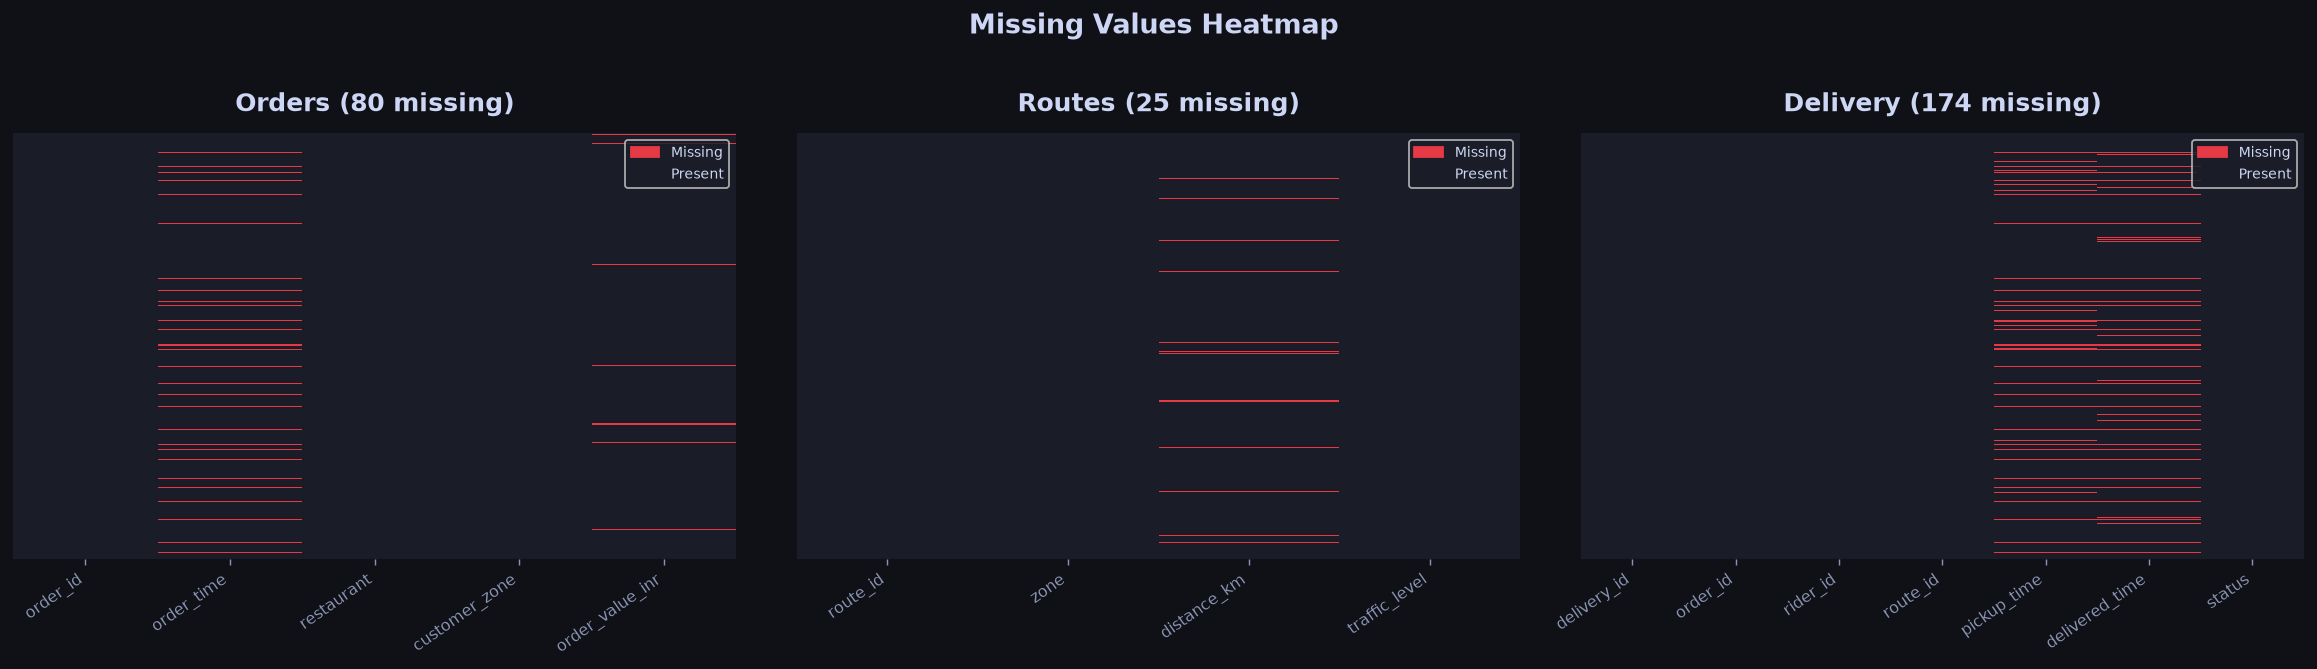

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Missing Values Heatmap', fontsize=15, fontweight='bold', y=1.02)

for ax, (name, df_plot) in zip(axes, [('Orders', orders), ('Routes', routes), ('Delivery', delivery)]):
    mask = df_plot.isnull()
    sns.heatmap(mask, ax=ax, cbar=False, yticklabels=False, cmap=['#1A1D27','#E63946'])
    ax.set_title(f'{name} ({mask.sum().sum()} missing)')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right', fontsize=9)
    red_p  = mpatches.Patch(color='#E63946', label='Missing')
    blue_p = mpatches.Patch(color='#1A1D27', label='Present')
    ax.legend(handles=[red_p, blue_p], loc='upper right', fontsize=8)

plt.tight_layout()
savefig('fig01_missing_heatmap')

## 4. Data Cleaning

In [8]:
# Step 1: Standardise zone names
ZONE_MAP = {
    'north':'North','nrth':'North','south':'South','sth':'South',
    'east':'East','east zone':'East','west':'West','central':'Central',
    'airport':'Airport','suburbs':'Suburbs','downtown':'Downtown','down town':'Downtown'
}

def standardise_zone(val):
    if pd.isna(val): return val
    return ZONE_MAP.get(val.strip().lower(), val.strip().title())

orders['customer_zone'] = orders['customer_zone'].apply(standardise_zone)
routes['zone']          = routes['zone'].apply(standardise_zone)
print('Step 1 Done - Zone names standardised')
print('Unique zones in orders:', sorted(orders['customer_zone'].dropna().unique()))

Step 1 Done - Zone names standardised
Unique zones in orders: ['Airport', 'Central', 'Downtown', 'East', 'North', 'South', 'Suburbs', 'West']


In [9]:
# Step 2: Remove duplicate order IDs
before = len(orders)
orders = orders.drop_duplicates(subset='order_id', keep='first').reset_index(drop=True)
print(f'Step 2 Done - Removed {before - len(orders)} duplicate order IDs. Remaining: {len(orders)}')

Step 2 Done - Removed 35 duplicate order IDs. Remaining: 1165


In [10]:
# Step 3: Fix negative order values
orders.loc[orders['order_value_inr'] < 0, 'order_value_inr'] = np.nan
orders['order_value_inr'] = orders.groupby('restaurant')['order_value_inr'].transform(
    lambda x: x.fillna(x.median()))
orders['order_value_inr'].fillna(orders['order_value_inr'].median(), inplace=True)
print(f'Step 3 Done - Negative/missing order values fixed. NaN remaining: {orders["order_value_inr"].isnull().sum()}')

Step 3 Done - Negative/missing order values fixed. NaN remaining: 0


In [11]:
# Step 4: Fix negative delivery durations
mask = delivery['delivered_time'] < delivery['pickup_time']
delivery.loc[mask, ['pickup_time','delivered_time']] = delivery.loc[mask, ['delivered_time','pickup_time']].values
print(f'Step 4 Done - Swapped {mask.sum()} rows with negative delivery durations')

Step 4 Done - Swapped 9 rows with negative delivery durations


In [12]:
# Step 5: Drop rows with missing timestamps
before_o = len(orders)
orders = orders.dropna(subset=['order_time']).reset_index(drop=True)
print(f'Step 5a - Dropped {before_o - len(orders)} orders missing order_time')

before_d = len(delivery)
delivery = delivery.dropna(subset=['pickup_time','delivered_time']).reset_index(drop=True)
print(f'Step 5b - Dropped {before_d - len(delivery)} deliveries missing timestamps. Remaining: {len(delivery)}')

Step 5a - Dropped 58 orders missing order_time
Step 5b - Dropped 114 deliveries missing timestamps. Remaining: 1086


In [13]:
# Step 6: Impute missing distances
routes['distance_km'] = routes.groupby('zone')['distance_km'].transform(
    lambda x: x.fillna(x.median()))
routes['distance_km'].fillna(routes['distance_km'].median(), inplace=True)
print(f'Step 6 Done - Missing distance_km imputed. NaN remaining: {routes["distance_km"].isnull().sum()}')

Step 6 Done - Missing distance_km imputed. NaN remaining: 0


In [14]:
# Step 7: Fill missing weather values
weather = weather.sort_values('datetime').reset_index(drop=True)
weather[['temperature_c','rain_flag','rainfall_mm','visibility_km']] = (
    weather[['temperature_c','rain_flag','rainfall_mm','visibility_km']].ffill().bfill())
riders['avg_rating'].fillna(
    riders.groupby('experience_level')['avg_rating'].transform('median'), inplace=True)
print(f'Step 7 Done - Weather NaN filled. Total weather NaN: {weather.isnull().sum().sum()}')
print(f'             Rider rating NaN filled. NaN remaining: {riders["avg_rating"].isnull().sum()}')

Step 7 Done - Weather NaN filled. Total weather NaN: 0
             Rider rating NaN filled. NaN remaining: 8


In [15]:
print('\nPost-Cleaning Summary:')
for name, df in [('orders',orders),('riders',riders),('routes',routes),('weather',weather),('delivery',delivery)]:
    print(f'  {name:12s}: {len(df):>5} rows, {df.isnull().sum().sum()} NaN values remaining')


Post-Cleaning Summary:
  orders      :  1107 rows, 0 NaN values remaining
  riders      :    80 rows, 8 NaN values remaining
  routes      :  1200 rows, 0 NaN values remaining
  weather     :  4345 rows, 0 NaN values remaining
  delivery    :  1086 rows, 0 NaN values remaining


## 5. Merge & Combine

In [16]:
df = (delivery
      .merge(orders,  on='order_id', how='inner')
      .merge(routes,  on='route_id', how='left')
      .merge(riders,  on='rider_id', how='left'))

print(f'After merging delivery+orders+routes+riders: {df.shape}')

# Join weather by nearest hour
df['order_hour_key'] = df['order_time'].dt.floor('h')
weather_h = weather.rename(columns={'datetime':'order_hour_key'})
df = df.merge(weather_h[['order_hour_key','temperature_c','rain_flag','rainfall_mm',
                           'visibility_km','weather_condition']],
              on='order_hour_key', how='left')

# Resolve zone
df['zone'] = df['customer_zone'].combine_first(df['zone'])
df.drop(columns=['customer_zone','order_hour_key'], inplace=True, errors='ignore')

# Fill remaining NaN
for col in ['temperature_c','rain_flag','rainfall_mm','visibility_km']:
    df[col].fillna(df[col].median(), inplace=True)
df['weather_condition'].fillna('Clear', inplace=True)

print(f'Final master dataset: {df.shape}')
display(df.head(3))

After merging delivery+orders+routes+riders: (1084, 18)
Final master dataset: (1084, 22)


,delivery_id,order_id,rider_id,route_id,pickup_time,delivered_time,status,order_time,restaurant,order_value_inr,zone,distance_km,traffic_level,experience_level,experience_years,shift,avg_rating,temperature_c,rain_flag,rainfall_mm,visibility_km,weather_condition
0,DLV00001,ORD00001,RDR062,RTE00001,2024-05-04 04:05:56.325804,2024-05-04 04:33:30.439308,Delivered,2024-05-04 03:56:41,Pasta Park,523.65,East,9.28,High,Senior,8.80,Morning,3.70,15.60,0.00,0.00,9.80,Cloudy
1,DLV00002,ORD00002,RDR005,RTE00002,2024-01-22 14:53:31.775123,2024-01-22 14:58:14.353153,Delivered,2024-01-22 14:50:25,Burger Barn,69.82,Airport,2.02,Medium,Senior,4.40,Morning,3.80,27.70,0.00,0.00,10.00,Clear
2,DLV00003,ORD00003,RDR047,RTE00003,2024-01-05 21:01:44.653941,2024-01-05 21:40:53.583676,Late,2024-01-05 20:33:30,Dim Sum Den,311.50,Suburbs,13.17,High,Mid,3.00,Evening,NaN,17.30,0.00,0.00,10.00,Clear


## 6. Descriptive Analysis

In [17]:
# Compute timing metrics
df['delivery_duration_min'] = ((df['delivered_time'] - df['pickup_time']).dt.total_seconds() / 60).round(2)
df['pickup_wait_min']       = ((df['pickup_time'] - df['order_time']).dt.total_seconds() / 60).round(2)
df['total_time_min']        = df['pickup_wait_min'] + df['delivery_duration_min']

# Remove invalid
df = df[(df['delivery_duration_min'] > 0) & (df['pickup_wait_min'] > 0)].reset_index(drop=True)
print(f'Valid records after timing filter: {len(df)}')

key_cols = ['delivery_duration_min','pickup_wait_min','total_time_min',
            'distance_km','order_value_inr','temperature_c','rainfall_mm','visibility_km']
display(df[key_cols].describe().round(2))

Valid records after timing filter: 1065


,delivery_duration_min,pickup_wait_min,total_time_min,distance_km,order_value_inr,temperature_c,rainfall_mm,visibility_km
count,1065.00,1065.00,1065.00,1065.00,1065.00,1065.00,1065.00,1065.00
mean,35.42,1116.15,1151.57,11.33,368.41,22.05,1.86,8.38
std,22.94,13320.22,13320.48,6.08,161.37,5.96,4.12,2.59
min,3.00,3.00,7.82,0.88,24.81,10.10,0.00,0.50
25%,17.36,10.39,33.00,6.22,239.51,16.80,0.00,8.30
50%,31.67,15.94,47.73,11.23,364.08,22.00,0.00,9.60
75%,48.83,20.92,66.99,16.43,503.84,27.20,1.60,10.00
max,90.00,228527.83,228541.37,21.99,767.53,35.30,44.80,10.00


In [18]:
print('Categorical Distributions:')
for col in ['status','traffic_level','experience_level','shift','weather_condition','zone']:
    print(f'\n{col}:')
    print(df[col].value_counts(dropna=False).to_string())

Categorical Distributions:

status:
status
Delivered    566
Late         315
Failed       184

traffic_level:
traffic_level
Medium       289
Very High    269
High         264
Low          243

experience_level:
experience_level
Mid       395
Senior    350
Junior    320

shift:
shift
Morning      303
Afternoon    303
Night        263
Evening      196

weather_condition:
weather_condition
Cloudy        366
Clear         343
Light Rain    209
Heavy Rain    147

zone:
zone
South       199
North       150
Central     139
East        121
Downtown    120
Suburbs     119
Airport     110
West        107


## 7. Key Visualizations

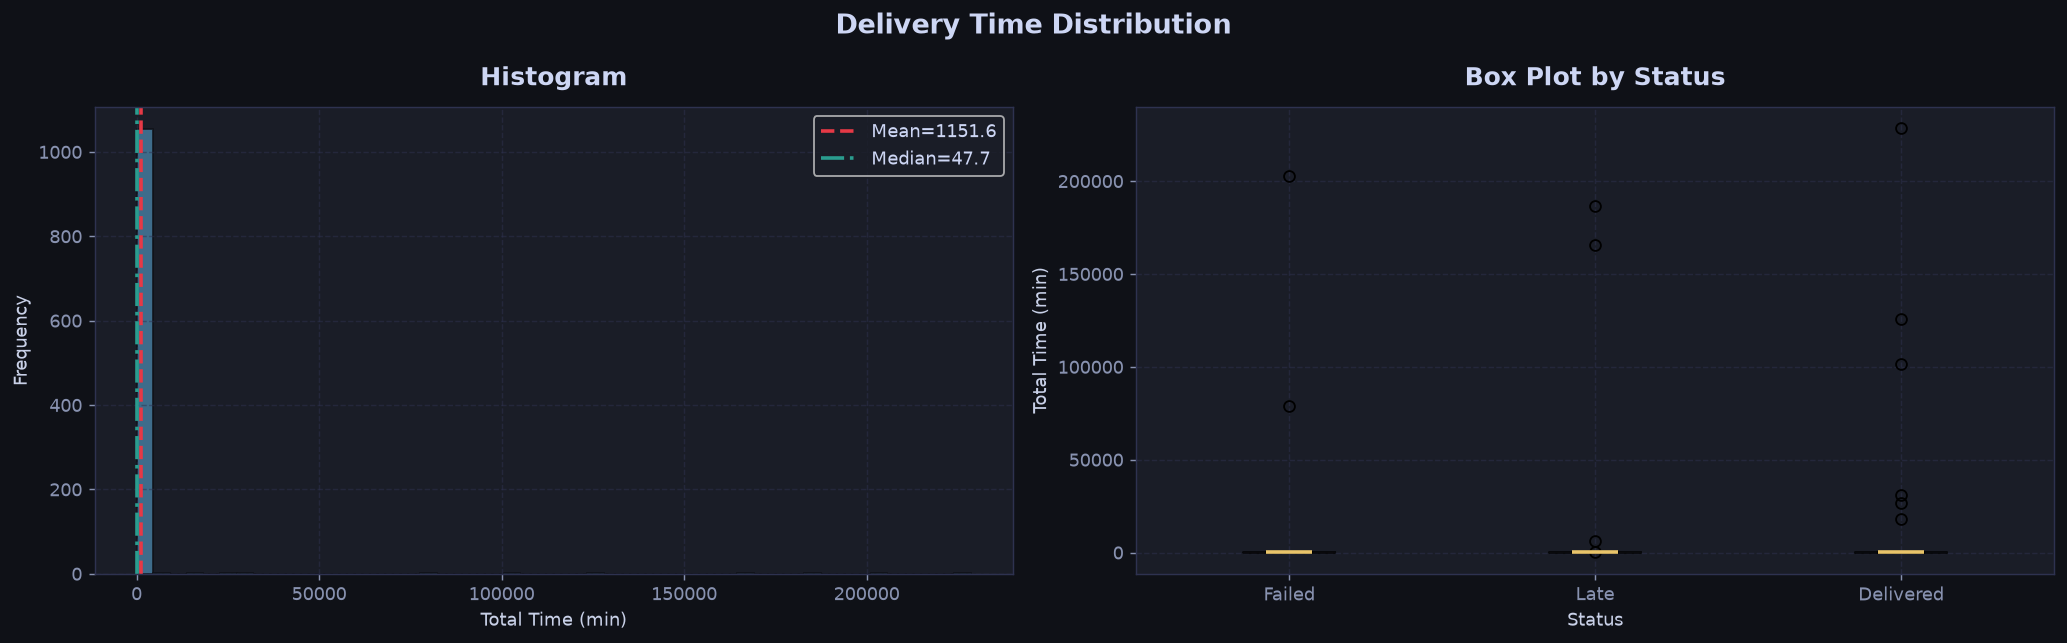

In [19]:
# Figure 2: Delivery time distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Delivery Time Distribution', fontsize=15, fontweight='bold')

axes[0].hist(df['total_time_min'], bins=50, color='#457B9D', edgecolor='#0F1117', alpha=0.85)
axes[0].axvline(df['total_time_min'].mean(),   color='#E63946', lw=2, ls='--', label=f'Mean={df["total_time_min"].mean():.1f}')
axes[0].axvline(df['total_time_min'].median(), color='#2A9D8F', lw=2, ls='-.', label=f'Median={df["total_time_min"].median():.1f}')
axes[0].set_xlabel('Total Time (min)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Histogram')
axes[0].legend()
axes[0].grid(True)

status_order = df.groupby('status')['total_time_min'].median().sort_values(ascending=False).index
data_s = [df[df['status']==s]['total_time_min'].dropna().values for s in status_order]
bp = axes[1].boxplot(data_s, patch_artist=True, notch=True, medianprops=dict(color='#E9C46A',lw=2))
for patch, c in zip(bp['boxes'], ['#E63946','#E9C46A','#2A9D8F']):
    patch.set_facecolor(c); patch.set_alpha(0.7)
axes[1].set_xticklabels(status_order)
axes[1].set_xlabel('Status')
axes[1].set_ylabel('Total Time (min)')
axes[1].set_title('Box Plot by Status')
axes[1].grid(True)

plt.tight_layout()
savefig('fig02_delivery_time_dist')

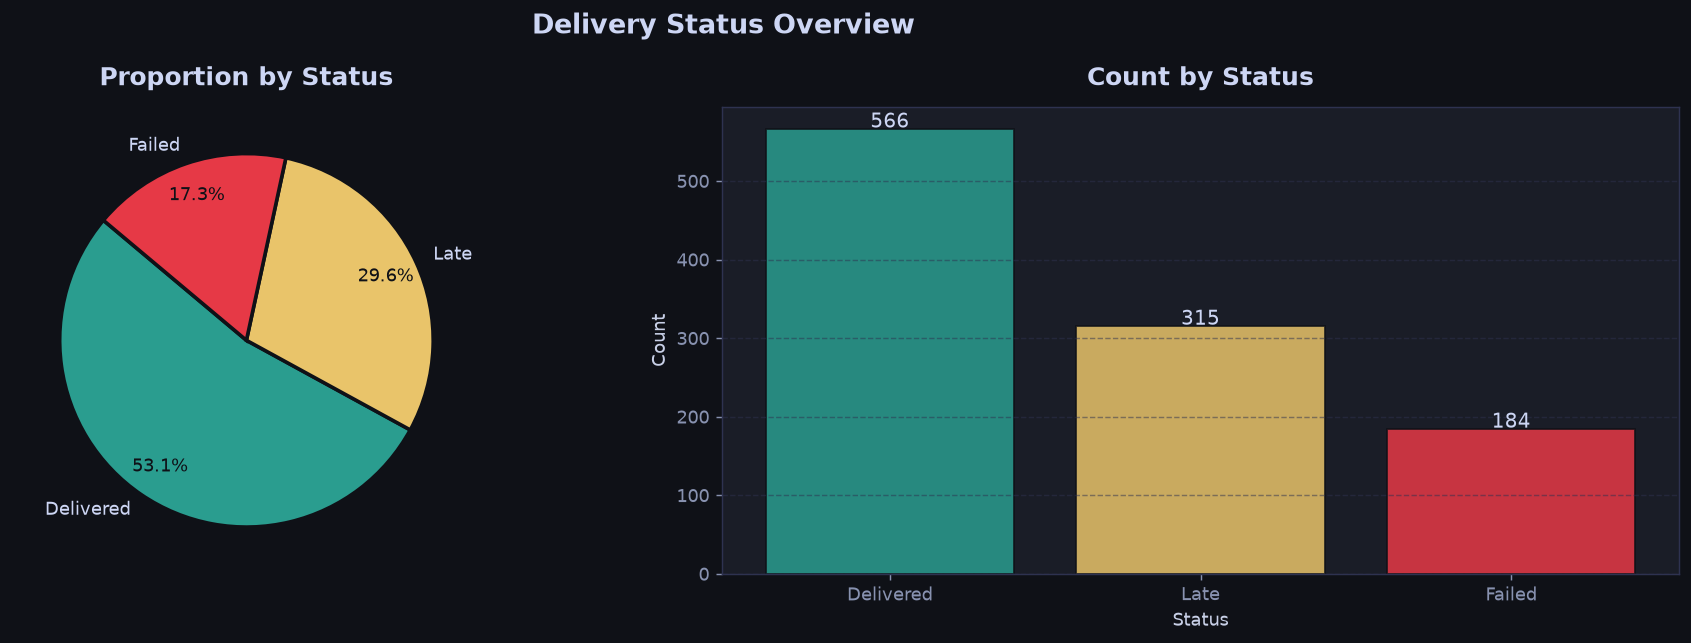

In [20]:
# Figure 3: Status Distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Delivery Status Overview', fontsize=15, fontweight='bold')

sc = df['status'].value_counts()
c_pie = ['#2A9D8F','#E9C46A','#E63946']

wedges, texts, ats = axes[0].pie(sc.values, labels=sc.index, autopct='%1.1f%%',
                                  colors=c_pie, startangle=140,
                                  wedgeprops=dict(edgecolor='#0F1117',linewidth=2),
                                  pctdistance=0.82)
for at in ats: at.set_color('#0F1117'); at.set_fontsize(10)
axes[0].set_title('Proportion by Status')

bars = axes[1].bar(sc.index, sc.values, color=c_pie, edgecolor='#0F1117', alpha=0.85)
for bar in bars:
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+2, f'{int(bar.get_height())}',
                 ha='center', fontsize=11)
axes[1].set_xlabel('Status')
axes[1].set_ylabel('Count')
axes[1].set_title('Count by Status')
axes[1].grid(True, axis='y')

plt.tight_layout()
savefig('fig03_status_distribution')

## 8. Use-Case Analytical Questions

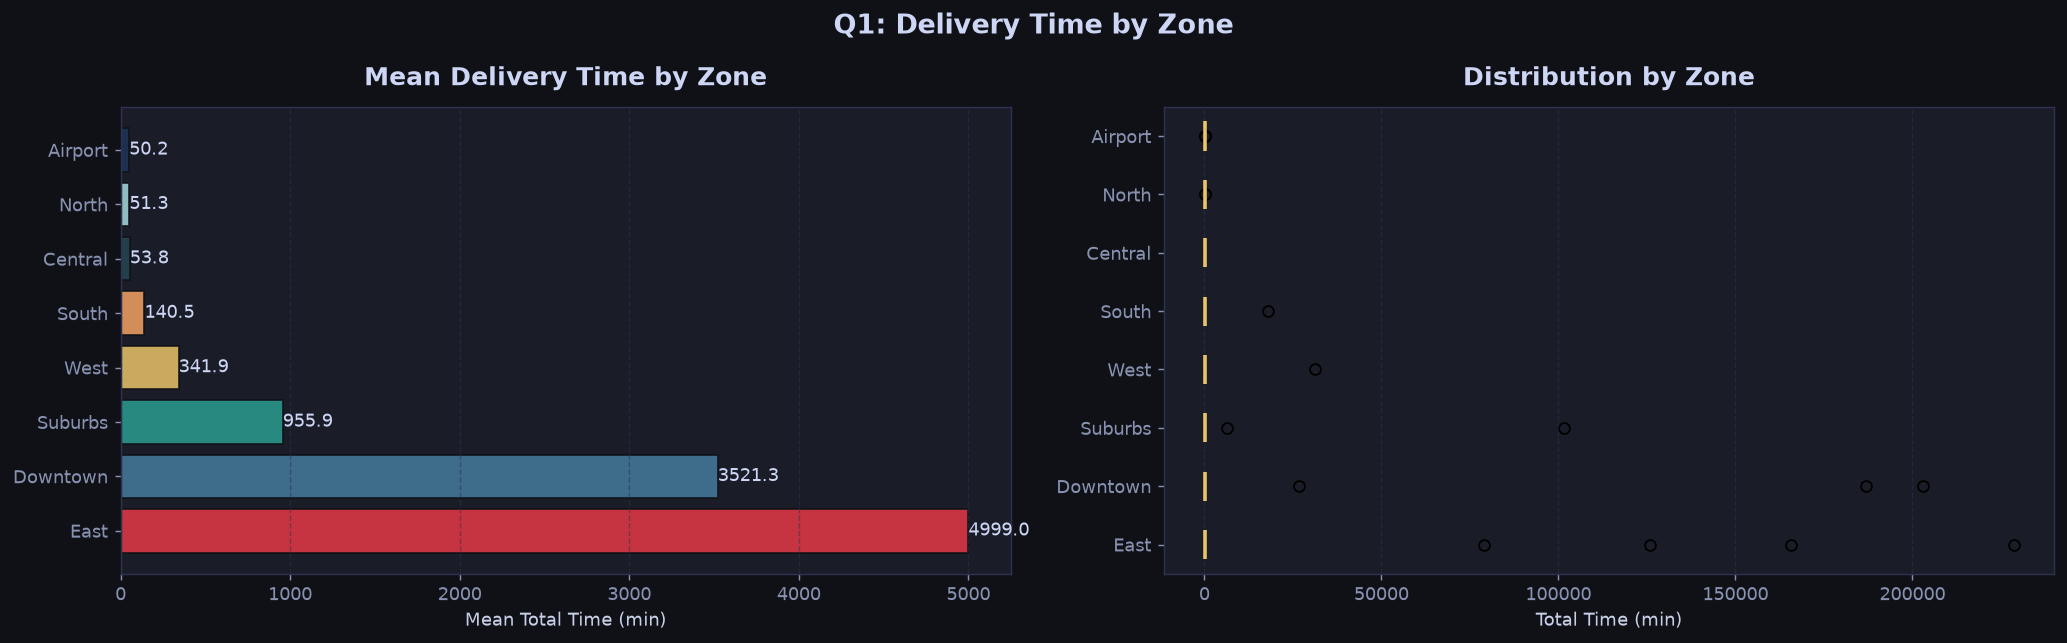

,Zone,Mean Time,Median Time,Orders
0,East,4999.02,44.76,121
1,Downtown,3521.30,50.85,120
2,Suburbs,955.90,49.46,119
3,West,341.87,47.54,107
4,South,140.52,46.56,199
5,Central,53.83,50.44,139
6,North,51.25,48.88,150
7,Airport,50.18,44.50,110


In [21]:
# Q1: Which zones have longer delivery times?
zone_time = (df.groupby('zone')['total_time_min']
               .agg(['mean','median','count'])
               .sort_values('mean', ascending=False)
               .reset_index())
zone_time.columns = ['Zone','Mean Time','Median Time','Orders']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Q1: Delivery Time by Zone', fontsize=15, fontweight='bold')

c_z = [PALETTE[i % len(PALETTE)] for i in range(len(zone_time))]
axes[0].barh(zone_time['Zone'], zone_time['Mean Time'], color=c_z, edgecolor='#0F1117', alpha=0.85)
for bar, val in zip(axes[0].patches, zone_time['Mean Time']):
    axes[0].text(val+0.3, bar.get_y()+bar.get_height()/2, f'{val:.1f}', va='center', fontsize=10)
axes[0].set_xlabel('Mean Total Time (min)')
axes[0].set_title('Mean Delivery Time by Zone')
axes[0].grid(True, axis='x')

data_z = [df[df['zone']==z]['total_time_min'].dropna().values for z in zone_time['Zone']]
bp2 = axes[1].boxplot(data_z, patch_artist=True, vert=False, medianprops=dict(color='#E9C46A',lw=2))
for patch, c in zip(bp2['boxes'], c_z): patch.set_facecolor(c); patch.set_alpha(0.6)
axes[1].set_yticklabels(zone_time['Zone'])
axes[1].set_xlabel('Total Time (min)')
axes[1].set_title('Distribution by Zone')
axes[1].grid(True, axis='x')

plt.tight_layout()
savefig('fig04_zone_delivery_time')
display(zone_time)

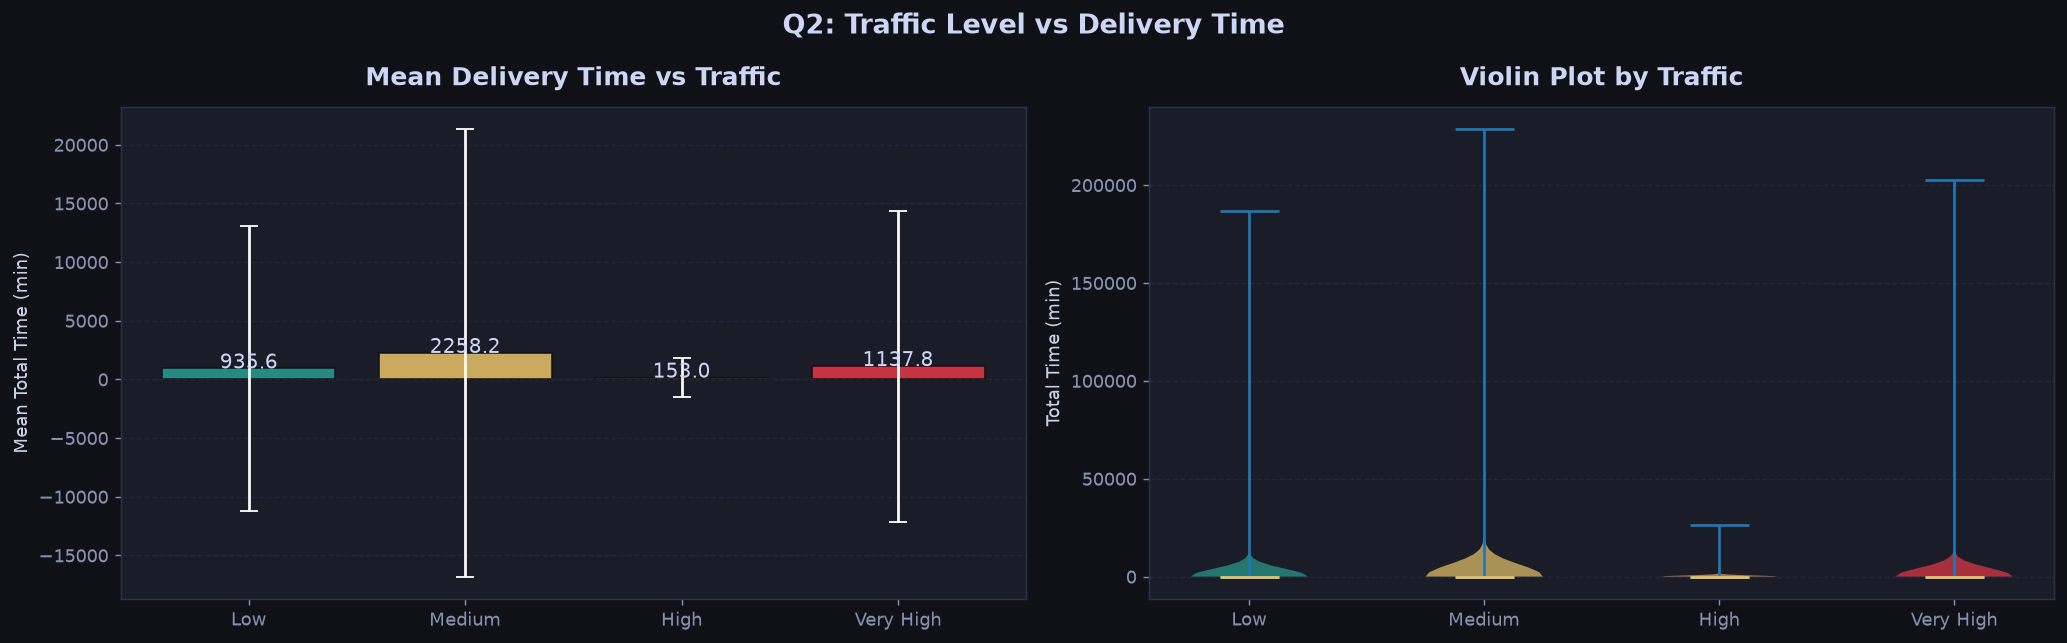

,mean,median,std,count
traffic_level,,,,
Low,935.64,39.40,12141.73,243
Medium,2258.17,44.70,19068.94,289
High,152.99,51.67,1635.95,264
Very High,1137.77,69.04,13251.13,269


In [22]:
# Q2: Traffic impact
traffic_order = ['Low','Medium','High','Very High']
t_colors = ['#2A9D8F','#E9C46A','#F4A261','#E63946']
traffic_time = df.groupby('traffic_level')['total_time_min'].agg(['mean','median','std','count']).reindex(traffic_order)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Q2: Traffic Level vs Delivery Time', fontsize=15, fontweight='bold')

axes[0].bar(traffic_order, traffic_time['mean'], color=t_colors, edgecolor='#0F1117', alpha=0.85)
axes[0].errorbar(traffic_order, traffic_time['mean'], yerr=traffic_time['std'],
                 fmt='none', color='white', capsize=5, lw=1.5)
for i, m in enumerate(traffic_time['mean']):
    axes[0].text(i, m+0.5, f'{m:.1f}', ha='center', fontsize=11)
axes[0].set_ylabel('Mean Total Time (min)')
axes[0].set_title('Mean Delivery Time vs Traffic')
axes[0].grid(True, axis='y')

data_t = [df[df['traffic_level']==t]['total_time_min'].dropna().values for t in traffic_order]
parts = axes[1].violinplot(data_t, positions=range(len(traffic_order)), showmedians=True)
for pc, col in zip(parts['bodies'], t_colors): pc.set_facecolor(col); pc.set_alpha(0.7)
parts['cmedians'].set_color('#E9C46A')
axes[1].set_xticks(range(len(traffic_order)))
axes[1].set_xticklabels(traffic_order)
axes[1].set_ylabel('Total Time (min)')
axes[1].set_title('Violin Plot by Traffic')
axes[1].grid(True, axis='y')

plt.tight_layout()
savefig('fig05_traffic_impact')
display(traffic_time.round(2))

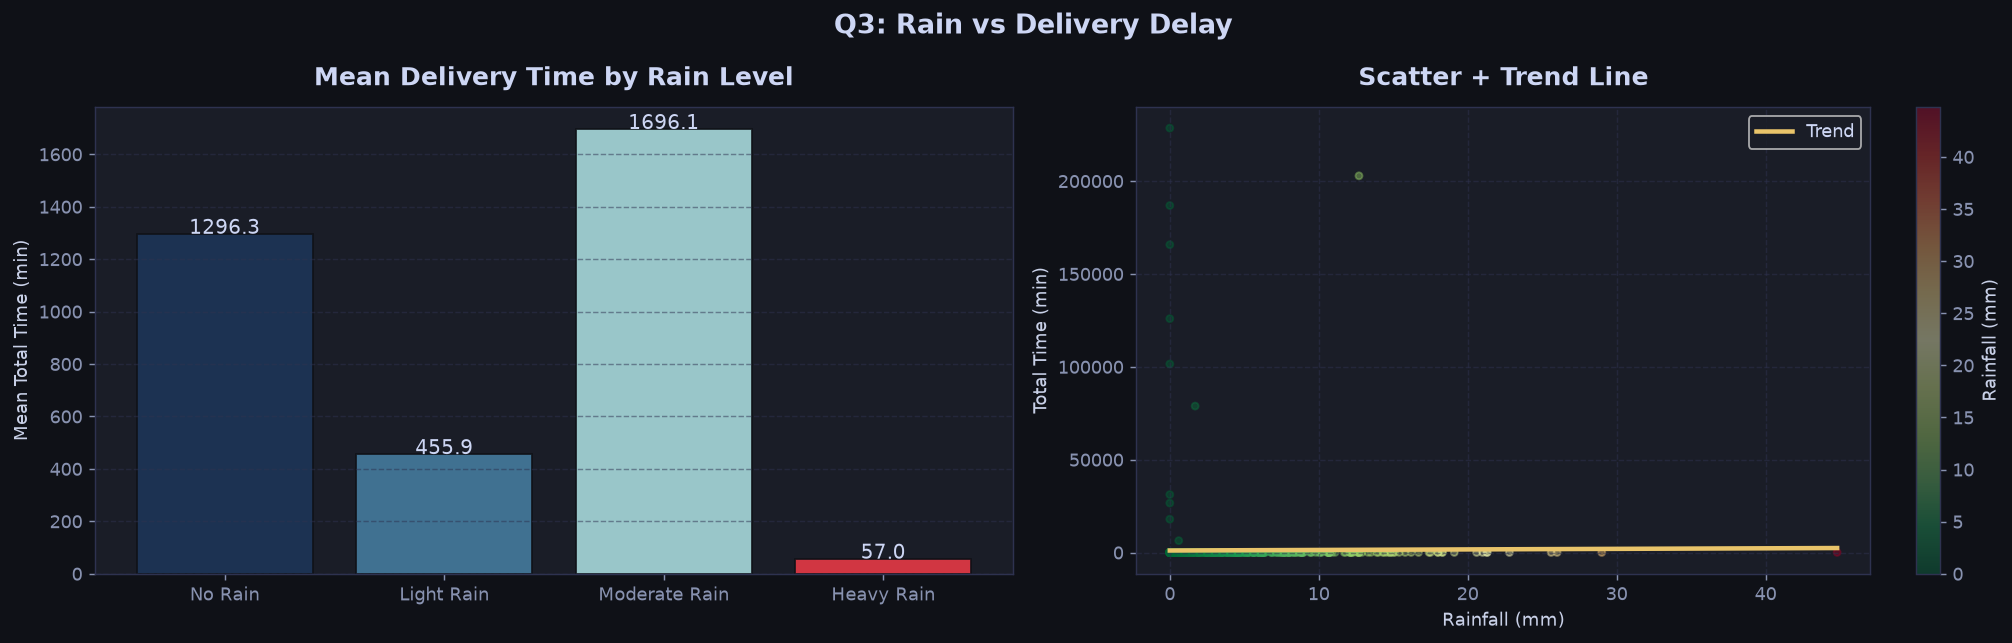

T-Test (No Rain vs Rain): t=0.385, p=0.7004
No significant difference.


In [23]:
# Q3: Does rain increase delay?
df['rain_category'] = pd.cut(df['rainfall_mm'], bins=[-np.inf,0,5,15,np.inf],
                               labels=['No Rain','Light Rain','Moderate Rain','Heavy Rain'])

rain_labels = ['No Rain','Light Rain','Moderate Rain','Heavy Rain']
rain_colors = ['#1D3557','#457B9D','#A8DADC','#E63946']
rain_means  = [df[df['rain_category']==r]['total_time_min'].mean() for r in rain_labels]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Q3: Rain vs Delivery Delay', fontsize=15, fontweight='bold')

axes[0].bar(rain_labels, rain_means, color=rain_colors, edgecolor='#0F1117', alpha=0.9)
for i, m in enumerate(rain_means):
    axes[0].text(i, m+0.4, f'{m:.1f}', ha='center', fontsize=11)
axes[0].set_ylabel('Mean Total Time (min)')
axes[0].set_title('Mean Delivery Time by Rain Level')
axes[0].grid(True, axis='y')

sc = axes[1].scatter(df['rainfall_mm'], df['total_time_min'], c=df['rainfall_mm'],
                     cmap='RdYlGn_r', alpha=0.4, s=15)
z = np.polyfit(df['rainfall_mm'], df['total_time_min'], 1)
p = np.poly1d(z)
xl = np.linspace(0, df['rainfall_mm'].max(), 100)
axes[1].plot(xl, p(xl), color='#E9C46A', lw=2.5, label='Trend')
plt.colorbar(sc, ax=axes[1], label='Rainfall (mm)')
axes[1].set_xlabel('Rainfall (mm)')
axes[1].set_ylabel('Total Time (min)')
axes[1].set_title('Scatter + Trend Line')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
savefig('fig06_rain_impact')

no_rain  = df[df['rain_flag'] < 0.5]['total_time_min'].dropna()
yes_rain = df[df['rain_flag'] >= 0.5]['total_time_min'].dropna()
t_stat, p_val = stats.ttest_ind(no_rain, yes_rain)
print(f'T-Test (No Rain vs Rain): t={t_stat:.3f}, p={p_val:.4f}')
print('Rain significantly increases delivery time.' if p_val < 0.05 else 'No significant difference.')

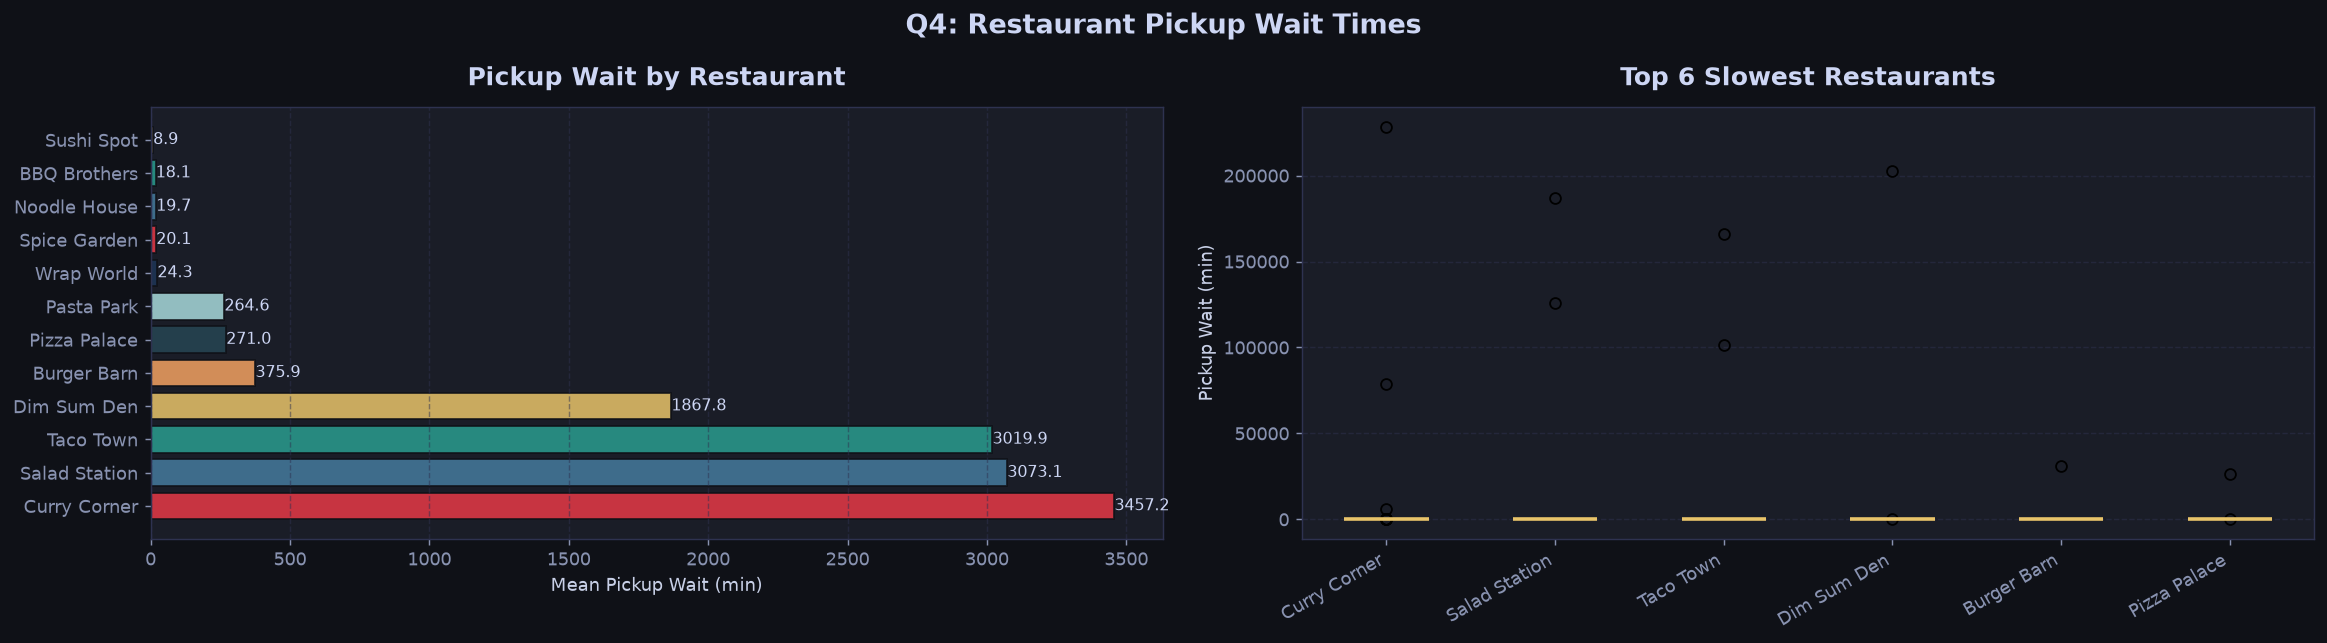

,Restaurant,Mean Wait,Median Wait,Orders
0,Curry Corner,3457.18,11.32,91
1,Salad Station,3073.05,7.40,102
2,Taco Town,3019.86,18.06,89
3,Dim Sum Den,1867.78,24.91,110
4,Burger Barn,375.85,9.23,85
5,Pizza Palace,270.97,14.98,104
6,Pasta Park,264.58,12.05,71
7,Wrap World,24.33,24.02,87
8,Spice Garden,20.09,20.01,79
9,Noodle House,19.72,20.08,69


In [24]:
# Q4: Restaurant pickup times
rest_pickup = (df.groupby('restaurant')['pickup_wait_min']
               .agg(['mean','median','count'])
               .sort_values('mean', ascending=False)
               .reset_index())
rest_pickup.columns = ['Restaurant','Mean Wait','Median Wait','Orders']

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
fig.suptitle('Q4: Restaurant Pickup Wait Times', fontsize=15, fontweight='bold')

c_r = [PALETTE[i % len(PALETTE)] for i in range(len(rest_pickup))]
axes[0].barh(rest_pickup['Restaurant'], rest_pickup['Mean Wait'], color=c_r, edgecolor='#0F1117', alpha=0.85)
for bar, (val, n) in zip(axes[0].patches, zip(rest_pickup['Mean Wait'], rest_pickup['Orders'])):
    axes[0].text(val+0.1, bar.get_y()+bar.get_height()/2, f'{val:.1f}', va='center', fontsize=9)
axes[0].set_xlabel('Mean Pickup Wait (min)')
axes[0].set_title('Pickup Wait by Restaurant')
axes[0].grid(True, axis='x')

top6 = rest_pickup['Restaurant'].head(6).tolist()
d_r = [df[df['restaurant']==r]['pickup_wait_min'].dropna().values for r in top6]
bp3 = axes[1].boxplot(d_r, patch_artist=True, medianprops=dict(color='#E9C46A',lw=2))
for patch, c in zip(bp3['boxes'], c_r[:6]): patch.set_facecolor(c); patch.set_alpha(0.7)
axes[1].set_xticklabels(top6, rotation=30, ha='right')
axes[1].set_ylabel('Pickup Wait (min)')
axes[1].set_title('Top 6 Slowest Restaurants')
axes[1].grid(True, axis='y')

plt.tight_layout()
savefig('fig07_restaurant_pickup')
display(rest_pickup)

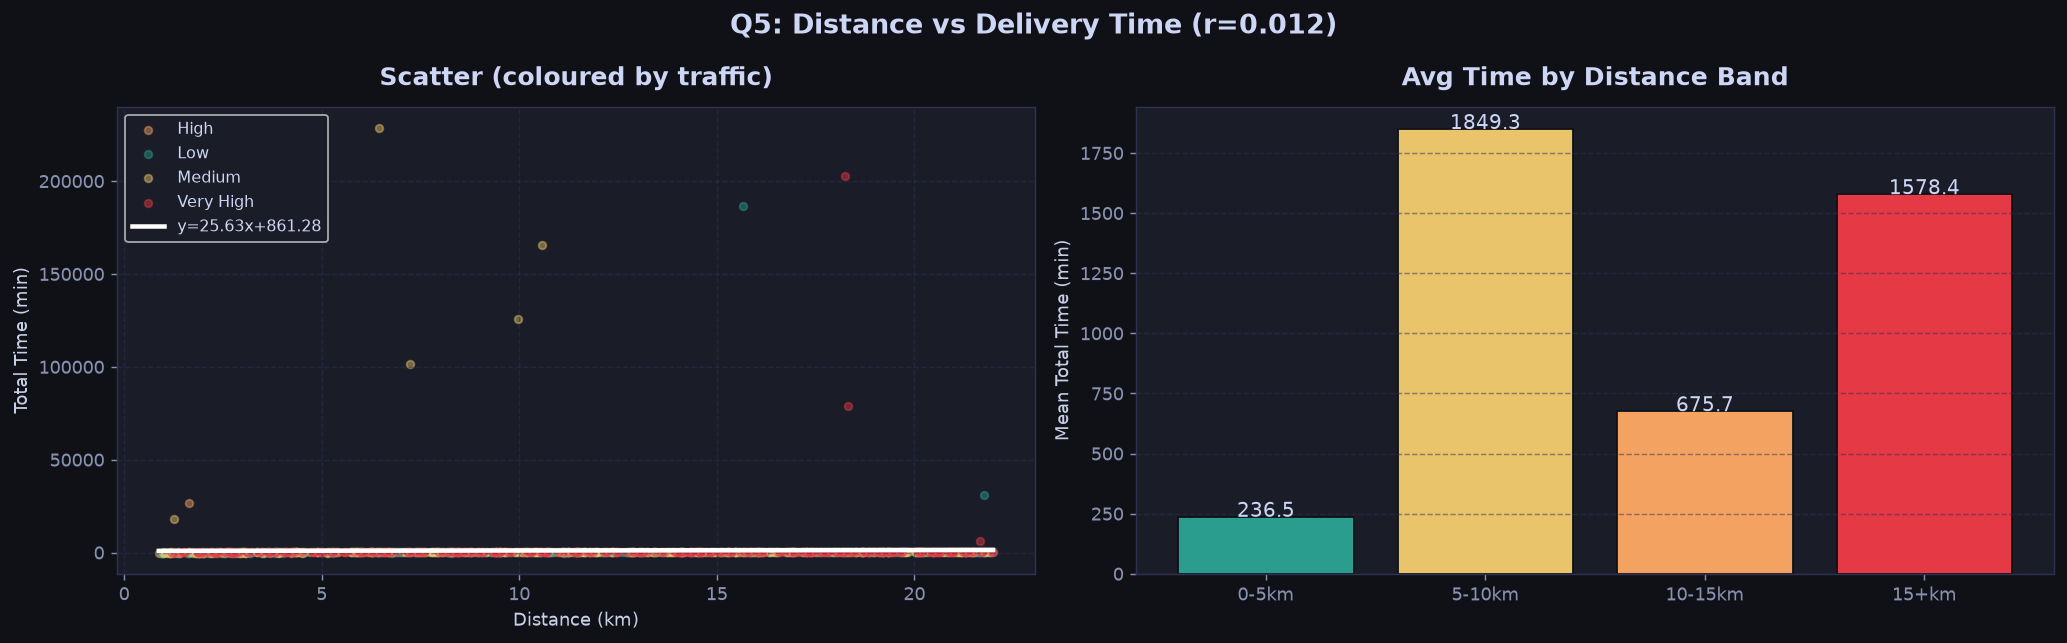

Regression: slope=25.628 min/km, R2=0.000


In [25]:
# Q5: Distance vs delivery time
corr_val = df[['distance_km','total_time_min']].corr().iloc[0,1]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle(f'Q5: Distance vs Delivery Time (r={corr_val:.3f})', fontsize=15, fontweight='bold')

tc_map = {'Low':'#2A9D8F','Medium':'#E9C46A','High':'#F4A261','Very High':'#E63946'}
for traf, grp in df.groupby('traffic_level'):
    axes[0].scatter(grp['distance_km'], grp['total_time_min'],
                    color=tc_map.get(traf,'#888'), alpha=0.45, s=18, label=traf)
slope, intercept, r_val, p_val, se = stats.linregress(df['distance_km'], df['total_time_min'])
xr = np.linspace(df['distance_km'].min(), df['distance_km'].max(), 100)
axes[0].plot(xr, slope*xr+intercept, color='white', lw=2.5, label=f'y={slope:.2f}x+{intercept:.2f}')
axes[0].set_xlabel('Distance (km)')
axes[0].set_ylabel('Total Time (min)')
axes[0].set_title('Scatter (coloured by traffic)')
axes[0].legend(fontsize=9)
axes[0].grid(True)

df['dist_bin'] = pd.cut(df['distance_km'], bins=[0,5,10,15,22], labels=['0-5km','5-10km','10-15km','15+km'])
d_bins = df.groupby('dist_bin', observed=True)['total_time_min'].mean()
axes[1].bar(d_bins.index, d_bins.values, color=['#2A9D8F','#E9C46A','#F4A261','#E63946'], edgecolor='#0F1117')
for i, v in enumerate(d_bins.values):
    axes[1].text(i, v+0.3, f'{v:.1f}', ha='center', fontsize=11)
axes[1].set_ylabel('Mean Total Time (min)')
axes[1].set_title('Avg Time by Distance Band')
axes[1].grid(True, axis='y')

plt.tight_layout()
savefig('fig08_distance_vs_time')
print(f'Regression: slope={slope:.3f} min/km, R2={r_val**2:.3f}')

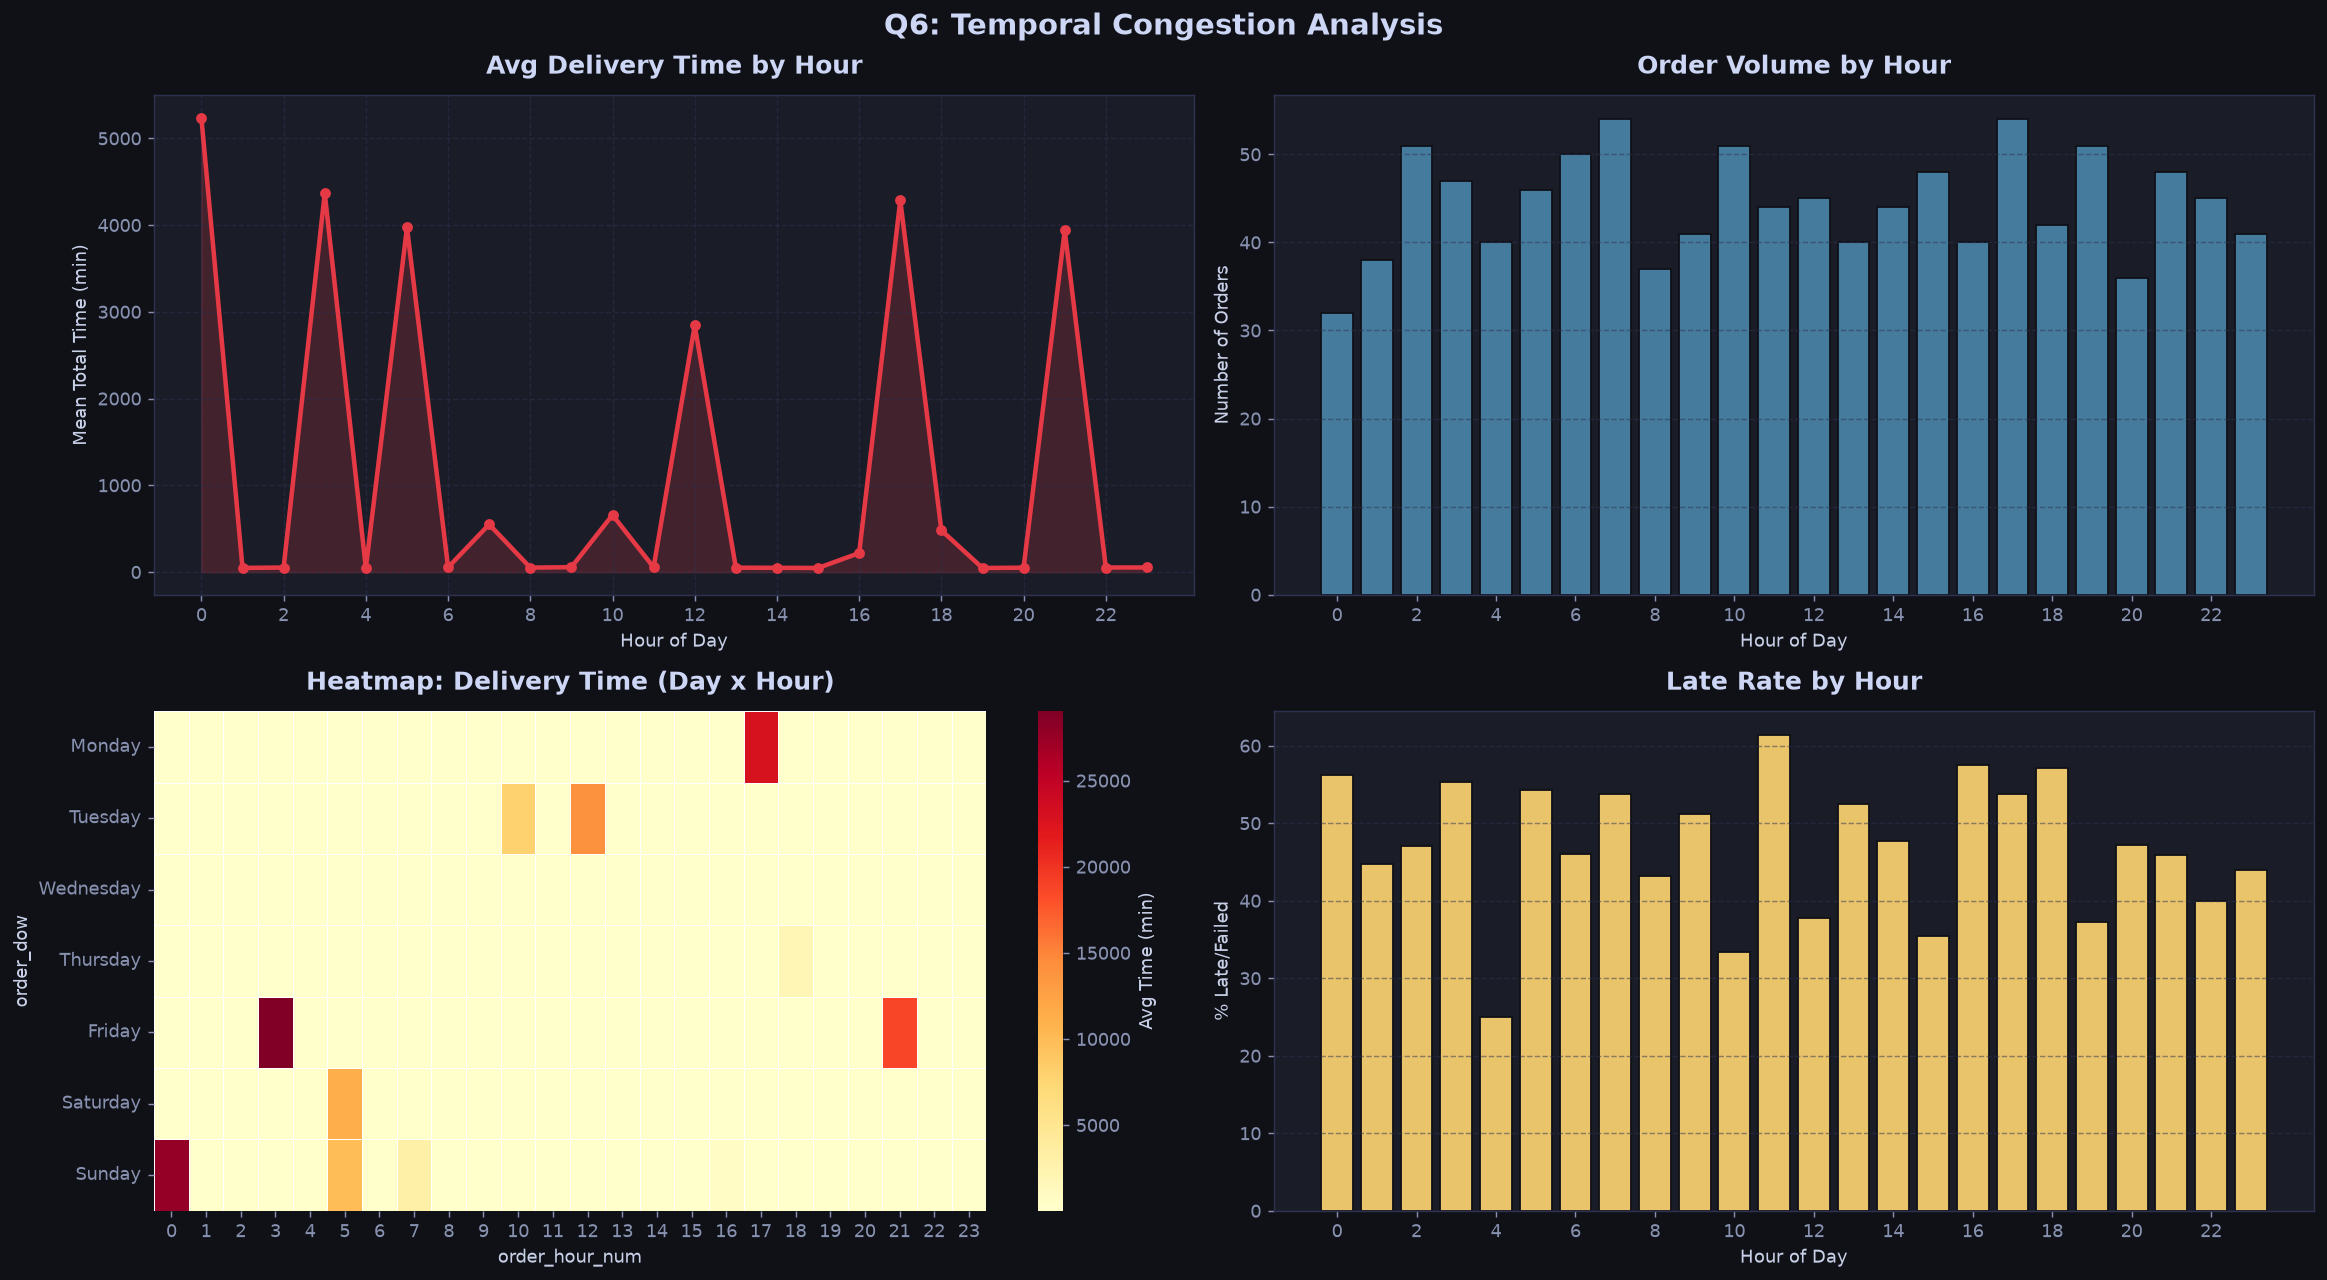

Peak congestion hour: 0:00
Peak order volume: 7:00


In [26]:
# Q6: Temporal congestion analysis
df['order_hour_num'] = df['order_time'].dt.hour
df['order_dow']      = df['order_time'].dt.day_name()

hourly = df.groupby('order_hour_num').agg(
    avg_time  = ('total_time_min','mean'),
    order_vol = ('order_id','count'),
    pct_late  = ('status', lambda x: (x.isin(['Late','Failed'])).mean()*100)
).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
fig.suptitle('Q6: Temporal Congestion Analysis', fontsize=16, fontweight='bold')

axes[0,0].plot(hourly['order_hour_num'], hourly['avg_time'], color='#E63946', lw=2.5, marker='o', ms=5)
axes[0,0].fill_between(hourly['order_hour_num'], hourly['avg_time'], alpha=0.2, color='#E63946')
axes[0,0].set_xlabel('Hour of Day')
axes[0,0].set_ylabel('Mean Total Time (min)')
axes[0,0].set_title('Avg Delivery Time by Hour')
axes[0,0].set_xticks(range(0,24,2))
axes[0,0].grid(True)

axes[0,1].bar(hourly['order_hour_num'], hourly['order_vol'], color='#457B9D', edgecolor='#0F1117')
axes[0,1].set_xlabel('Hour of Day')
axes[0,1].set_ylabel('Number of Orders')
axes[0,1].set_title('Order Volume by Hour')
axes[0,1].set_xticks(range(0,24,2))
axes[0,1].grid(True, axis='y')

day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
heat = (df.groupby(['order_dow','order_hour_num'])['total_time_min']
          .mean().unstack(fill_value=0).reindex(day_order))
sns.heatmap(heat, ax=axes[1,0], cmap='YlOrRd', linewidths=0.3, cbar_kws={'label':'Avg Time (min)'})
axes[1,0].set_title('Heatmap: Delivery Time (Day x Hour)')

axes[1,1].bar(hourly['order_hour_num'], hourly['pct_late'], color='#E9C46A', edgecolor='#0F1117')
axes[1,1].set_xlabel('Hour of Day')
axes[1,1].set_ylabel('% Late/Failed')
axes[1,1].set_title('Late Rate by Hour')
axes[1,1].set_xticks(range(0,24,2))
axes[1,1].grid(True, axis='y')

plt.tight_layout()
savefig('fig09_temporal_analysis')

print(f'Peak congestion hour: {hourly.loc[hourly["avg_time"].idxmax(),"order_hour_num"]}:00')
print(f'Peak order volume: {hourly.loc[hourly["order_vol"].idxmax(),"order_hour_num"]}:00')

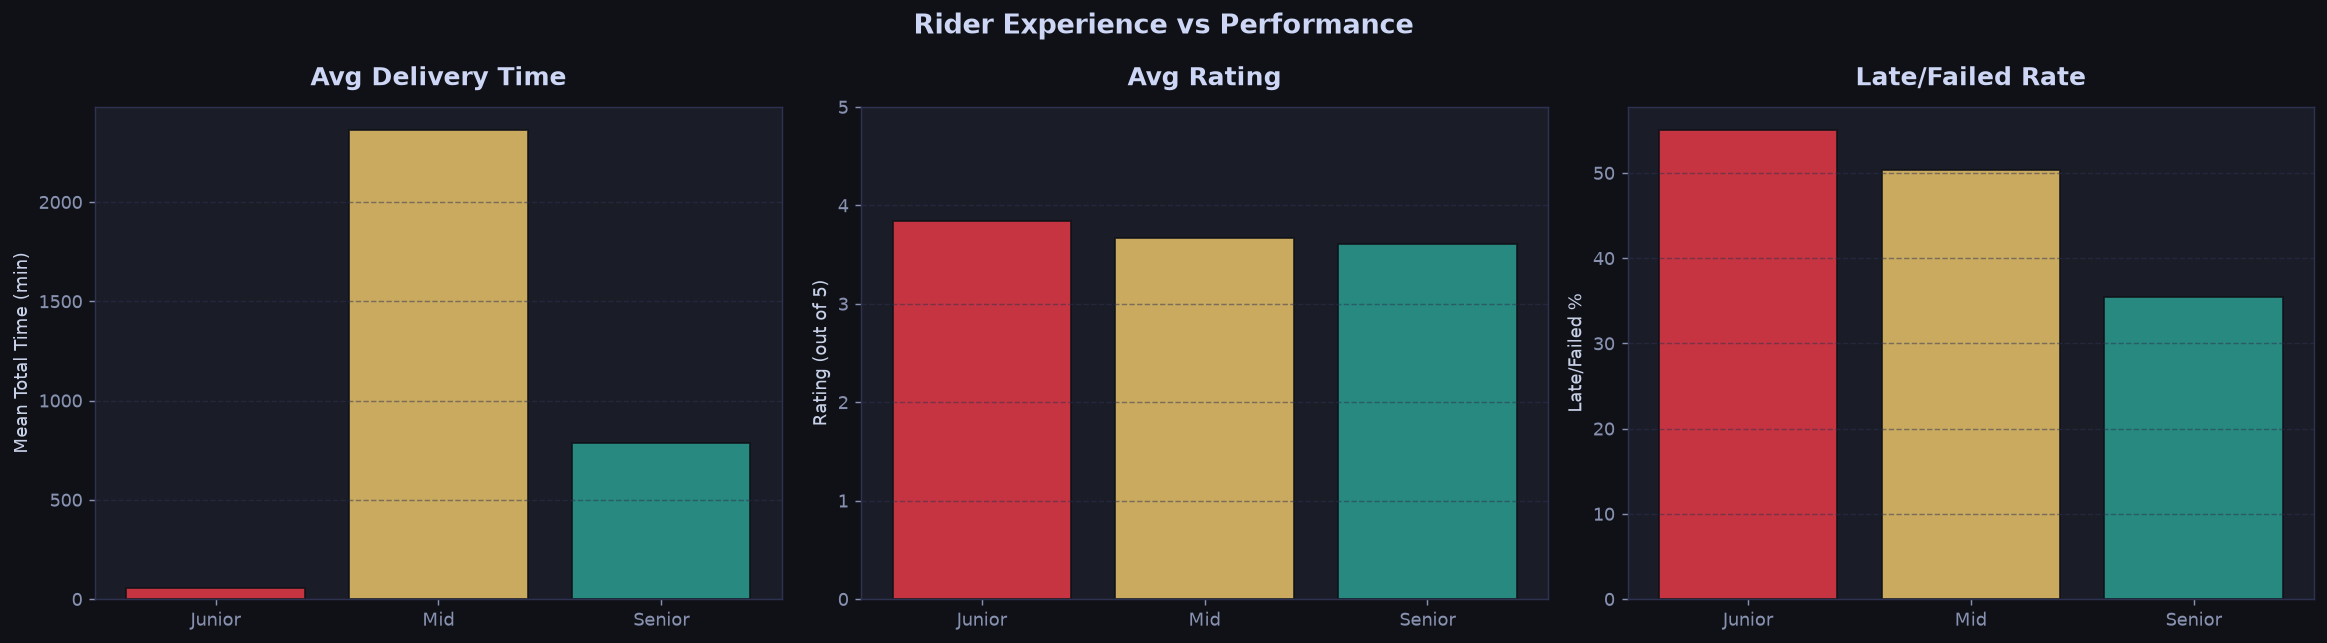

,avg_time,avg_rating,pct_late
experience_level,,,
Junior,56.15,3.84,55.00
Mid,2361.22,3.66,50.38
Senior,787.92,3.61,35.43


In [27]:
# Rider performance
rp = df.groupby('experience_level').agg(
    avg_time=('total_time_min','mean'),
    avg_rating=('avg_rating','mean'),
    pct_late=('status', lambda x: (x.isin(['Late','Failed'])).mean()*100)
).reindex(['Junior','Mid','Senior'])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Rider Experience vs Performance', fontsize=15, fontweight='bold')
exp_levels = ['Junior','Mid','Senior']
exp_colors = ['#E63946','#E9C46A','#2A9D8F']

for ax, col, title, ylabel in zip(axes,
    ['avg_time','avg_rating','pct_late'],
    ['Avg Delivery Time','Avg Rating','Late/Failed Rate'],
    ['Mean Total Time (min)','Rating (out of 5)','Late/Failed %']):
    ax.bar(exp_levels, rp[col], color=exp_colors, edgecolor='#0F1117', alpha=0.85)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(True, axis='y')

axes[1].set_ylim(0, 5)
plt.tight_layout()
savefig('fig10_rider_performance')
display(rp.round(2))

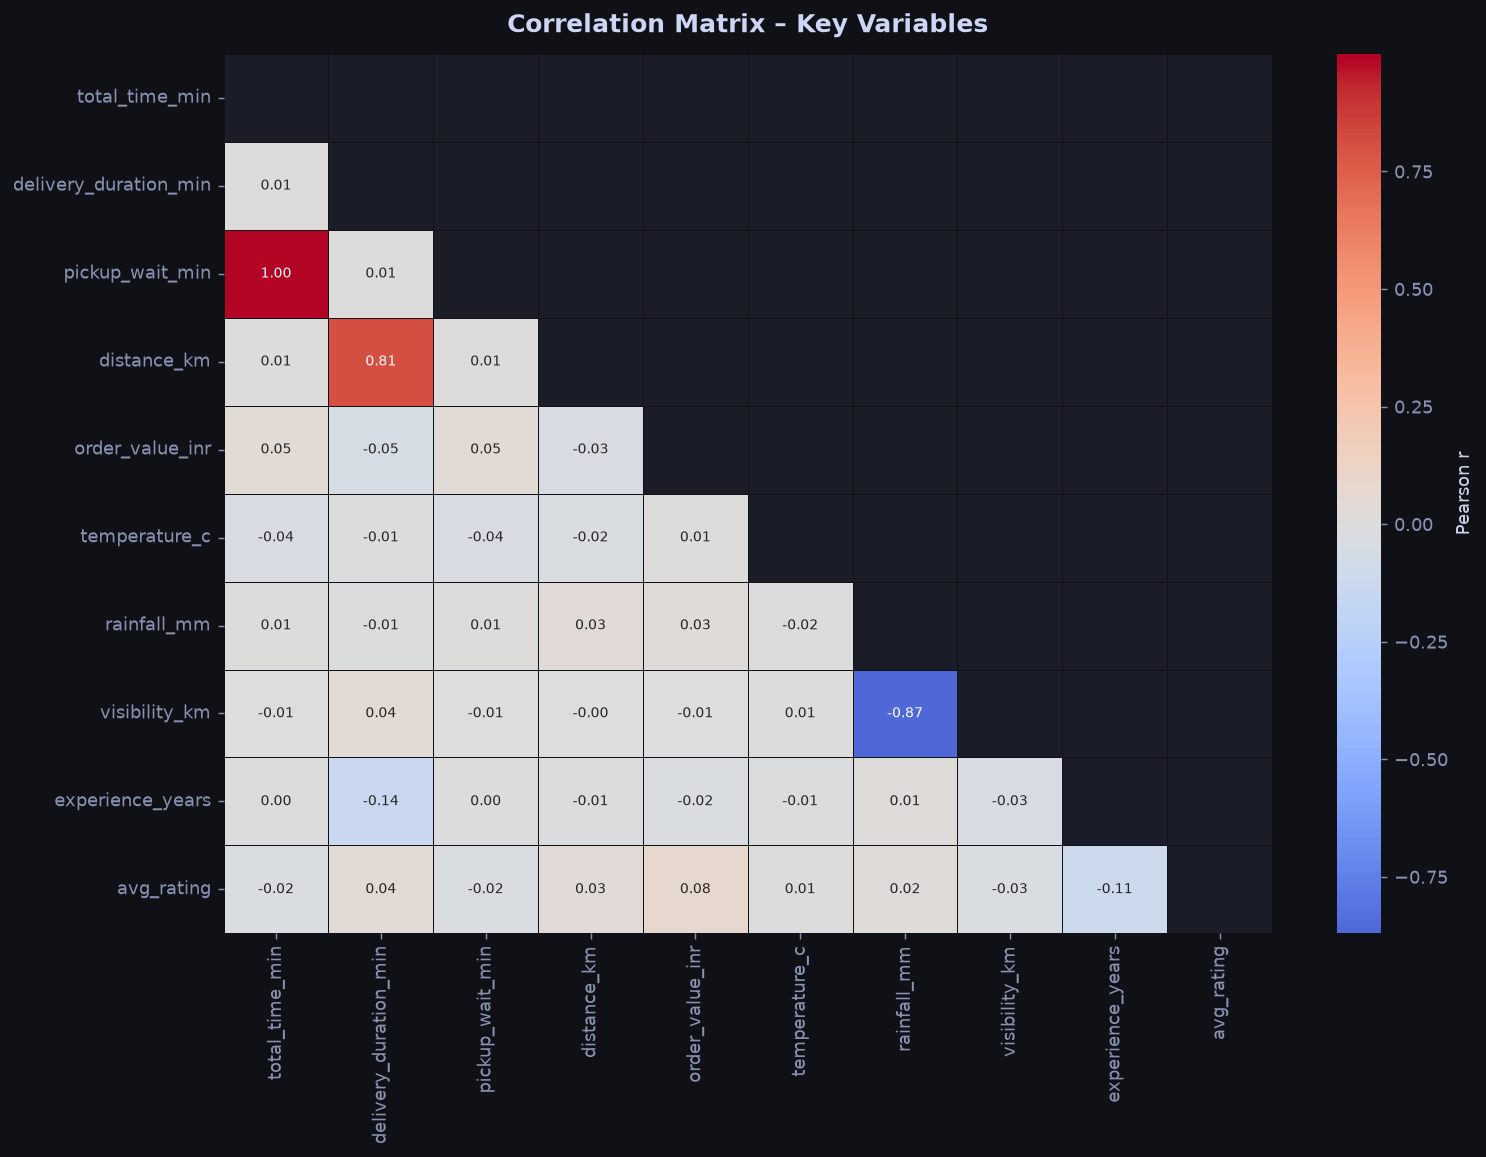

Correlations with total_time_min:
pickup_wait_min          1.00
order_value_inr          0.05
temperature_c           -0.04
avg_rating              -0.02
delivery_duration_min    0.01
distance_km              0.01
rainfall_mm              0.01
visibility_km           -0.01
experience_years         0.00
Name: total_time_min, dtype: float64


In [28]:
# Correlation heatmap
num_cols = ['total_time_min','delivery_duration_min','pickup_wait_min',
            'distance_km','order_value_inr','temperature_c',
            'rainfall_mm','visibility_km','experience_years','avg_rating']

corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', ax=ax, cmap='coolwarm',
            center=0, annot_kws={'size':8}, linewidths=0.5, linecolor='#0F1117',
            cbar_kws={'label':'Pearson r'})
ax.set_title('Correlation Matrix – Key Variables')
plt.tight_layout()
savefig('fig11_correlation_heatmap')
print('Correlations with total_time_min:')
print(corr['total_time_min'].drop('total_time_min').sort_values(key=abs, ascending=False).round(3))

## 9. Feature Engineering

In [29]:
# Temporal features
df['order_hour_num']    = df['order_time'].dt.hour
df['order_day_of_week'] = df['order_time'].dt.dayofweek
df['order_month']       = df['order_time'].dt.month
df['is_weekend']        = (df['order_day_of_week'] >= 5).astype(int)
df['is_peak_hour']      = df['order_hour_num'].apply(lambda h: 1 if (12<=h<=14) or (18<=h<=21) else 0)

def time_of_day(h):
    if 5<=h<12: return 'Morning'
    if 12<=h<17: return 'Afternoon'
    if 17<=h<21: return 'Evening'
    return 'Night'

df['time_of_day'] = df['order_hour_num'].apply(time_of_day)
print('Temporal features created:', ['order_hour_num','order_day_of_week','order_month','is_weekend','is_peak_hour','time_of_day'])

Temporal features created: ['order_hour_num', 'order_day_of_week', 'order_month', 'is_weekend', 'is_peak_hour', 'time_of_day']


In [30]:
# Traffic + Distance features
traffic_num_map = {'Low':1,'Medium':2,'High':3,'Very High':4}
df['traffic_numeric']  = df['traffic_level'].map(traffic_num_map)
df['congestion_score'] = df['distance_km'] * df['traffic_numeric']
df['speed_kmpm']       = df['distance_km'] / df['delivery_duration_min'].replace(0, np.nan)
df['speed_kmpm'].fillna(df['speed_kmpm'].median(), inplace=True)
print('Traffic/distance features: traffic_numeric, congestion_score, speed_kmpm')

Traffic/distance features: traffic_numeric, congestion_score, speed_kmpm


In [31]:
# Weather features
df['bad_weather']      = ((df['rainfall_mm'] > 10) | (df['visibility_km'] < 3)).astype(int)
df['weather_severity'] = ((df['rainfall_mm'].clip(0,30)/30)*50 + ((10-df['visibility_km'].clip(0,10))/10)*50).round(2)
print(f'Weather features created. Bad weather rate: {df["bad_weather"].mean():.1%}')

Weather features created. Bad weather rate: 8.0%


In [32]:
# Rider performance index
exp_score_map = {'Junior':1,'Mid':2,'Senior':3}
df['rider_exp_score']       = df['experience_level'].map(exp_score_map)
df['rider_performance_idx'] = ((df['avg_rating']/5)*50 + (df['rider_exp_score']/3)*50).round(2)
print('Rider features: rider_exp_score, rider_performance_idx')

Rider features: rider_exp_score, rider_performance_idx


In [33]:
# Restaurant aggregated features
rest_stats = df.groupby('restaurant').agg(
    rest_avg_pickup  = ('pickup_wait_min','mean'),
    rest_order_count = ('order_id','count'),
    rest_late_rate   = ('status', lambda x: (x.isin(['Late','Failed'])).mean())
).round(3)
df = df.merge(rest_stats, on='restaurant', how='left')
print('Restaurant features: rest_avg_pickup, rest_order_count, rest_late_rate')
display(rest_stats.sort_values('rest_avg_pickup', ascending=False).head())

Restaurant features: rest_avg_pickup, rest_order_count, rest_late_rate


,rest_avg_pickup,rest_order_count,rest_late_rate
restaurant,,,
Curry Corner,3457.18,91,0.39
Salad Station,3073.05,102,0.30
Taco Town,3019.86,89,0.47
Dim Sum Den,1867.78,110,0.62
Burger Barn,375.85,85,0.42


In [34]:
# Zone aggregated features
zone_stats = df.groupby('zone').agg(
    zone_avg_time  = ('total_time_min','mean'),
    zone_late_rate = ('status', lambda x: (x.isin(['Late','Failed'])).mean()),
    zone_order_vol = ('order_id','count')
).round(3)
df = df.merge(zone_stats, on='zone', how='left')
print('Zone features: zone_avg_time, zone_late_rate, zone_order_vol')
display(zone_stats.sort_values('zone_avg_time', ascending=False))

Zone features: zone_avg_time, zone_late_rate, zone_order_vol


,zone_avg_time,zone_late_rate,zone_order_vol
zone,,,
East,4999.02,0.42,121
Downtown,3521.30,0.51,120
Suburbs,955.90,0.48,119
West,341.87,0.46,107
South,140.52,0.43,199
Central,53.83,0.52,139
North,51.25,0.49,150
Airport,50.18,0.46,110


In [35]:
# Target variable
SLA = 45
df['is_delayed'] = (df['total_time_min'] > SLA).astype(int)
print(f'Target: is_delayed (SLA={SLA} min)  |  Delayed: {df["is_delayed"].sum()} ({df["is_delayed"].mean():.1%})')

print('\nAll engineered features:')
eng = ['delivery_duration_min','pickup_wait_min','total_time_min',
       'order_hour_num','order_day_of_week','order_month','is_weekend','is_peak_hour','time_of_day',
       'traffic_numeric','congestion_score','speed_kmpm',
       'bad_weather','weather_severity',
       'rider_exp_score','rider_performance_idx',
       'rest_avg_pickup','rest_order_count','rest_late_rate',
       'zone_avg_time','zone_late_rate','zone_order_vol','is_delayed']
for f in eng: print(f'  * {f}')

Target: is_delayed (SLA=45 min)  |  Delayed: 588 (55.2%)

All engineered features:
  * delivery_duration_min
  * pickup_wait_min
  * total_time_min
  * order_hour_num
  * order_day_of_week
  * order_month
  * is_weekend
  * is_peak_hour
  * time_of_day
  * traffic_numeric
  * congestion_score
  * speed_kmpm
  * bad_weather
  * weather_severity
  * rider_exp_score
  * rider_performance_idx
  * rest_avg_pickup
  * rest_order_count
  * rest_late_rate
  * zone_avg_time
  * zone_late_rate
  * zone_order_vol
  * is_delayed


## 10. Encoding Categorical Variables

In [36]:
# Ordinal encoding
tod_map = {'Morning':0,'Afternoon':1,'Evening':2,'Night':3}
df['time_of_day_enc'] = df['time_of_day'].map(tod_map)

# Label encoding
le_status  = LabelEncoder()
le_weather = LabelEncoder()
df['status_enc']            = le_status.fit_transform(df['status'])
df['weather_condition_enc'] = le_weather.fit_transform(df['weather_condition'])

print('Ordinal: time_of_day_enc')
print('Label:   status_enc, weather_condition_enc')
print(f'  status    : {dict(zip(le_status.classes_, le_status.transform(le_status.classes_)))}')
print(f'  weather   : {dict(zip(le_weather.classes_, le_weather.transform(le_weather.classes_)))}')

Ordinal: time_of_day_enc
Label:   status_enc, weather_condition_enc
  status    : {'Delivered': np.int64(0), 'Failed': np.int64(1), 'Late': np.int64(2)}
  weather   : {'Clear': np.int64(0), 'Cloudy': np.int64(1), 'Heavy Rain': np.int64(2), 'Light Rain': np.int64(3)}


In [37]:
# One-hot encoding
ohe_cols = ['zone','restaurant','shift']
df_encoded = pd.get_dummies(df, columns=ohe_cols, prefix=ohe_cols, drop_first=True, dtype=int)
new_ohe = [c for c in df_encoded.columns if any(c.startswith(p+'_') for p in ohe_cols)]
print(f'One-hot encoding created {len(new_ohe)} columns for: {ohe_cols}')
print(f'Encoded dataset shape: {df_encoded.shape}')

One-hot encoding created 24 columns for: ['zone', 'restaurant', 'shift']
Encoded dataset shape: (1065, 69)


## 11. Feature Selection

In [38]:
EXCLUDE = ['delivery_id','order_id','rider_id','route_id',
           'order_time','pickup_time','delivered_time','order_hour_key',
           'total_time_min','delivery_duration_min','pickup_wait_min',
           'status','status_enc','is_delayed',
           'time_of_day','weather_condition','dist_bin','rain_category','order_dow']

feature_cols = [c for c in df_encoded.select_dtypes(include=[np.number]).columns if c not in EXCLUDE]
X = df_encoded[feature_cols].fillna(df_encoded[feature_cols].median())
y = df_encoded['total_time_min']

print(f'Feature matrix: {X.shape}')
for f in feature_cols: print(f'  - {f}')

Feature matrix: (1065, 49)
  - order_value_inr
  - distance_km
  - experience_years
  - avg_rating
  - temperature_c
  - rain_flag
  - rainfall_mm
  - visibility_km
  - order_hour_num
  - order_day_of_week
  - order_month
  - is_weekend
  - is_peak_hour
  - traffic_numeric
  - congestion_score
  - speed_kmpm
  - bad_weather
  - weather_severity
  - rider_exp_score
  - rider_performance_idx
  - rest_avg_pickup
  - rest_order_count
  - rest_late_rate
  - zone_avg_time
  - zone_late_rate
  - zone_order_vol
  - time_of_day_enc
  - weather_condition_enc
  - zone_Central
  - zone_Downtown
  - zone_East
  - zone_North
  - zone_South
  - zone_Suburbs
  - zone_West
  - restaurant_Burger Barn
  - restaurant_Curry Corner
  - restaurant_Dim Sum Den
  - restaurant_Noodle House
  - restaurant_Pasta Park
  - restaurant_Pizza Palace
  - restaurant_Salad Station
  - restaurant_Spice Garden
  - restaurant_Sushi Spot
  - restaurant_Taco Town
  - restaurant_Wrap World
  - shift_Evening
  - shift_Morning
 

In [39]:
# SelectKBest
skb = SelectKBest(f_regression, k='all')
skb.fit(X, y)
skb_scores = pd.Series(skb.scores_, index=feature_cols).sort_values(ascending=False)
print('Top 15 by F-Regression:')
display(skb_scores.head(15).round(2))

Top 15 by F-Regression:


zone_avg_time              18.48
zone_East                  11.50
rest_avg_pickup            11.04
order_month                 8.90
zone_Downtown               4.29
restaurant_Curry Corner     3.08
restaurant_Salad Station    2.43
order_value_inr             2.40
zone_order_vol              2.31
rest_order_count            2.00
restaurant_Taco Town        1.98
temperature_c               1.42
zone_South                  1.41
zone_North                  1.19
rest_late_rate              1.15
dtype: float64

In [40]:
# Random Forest importance
rf = RandomForestRegressor(n_estimators=150, max_depth=8, random_state=42, n_jobs=-1)
rf.fit(X, y)
rf_imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
print('Top 15 by Random Forest:')
display(rf_imp.head(15).round(4))

Top 15 by Random Forest:

avg_rating              0.13
congestion_score        0.11
temperature_c           0.07
order_value_inr         0.05
weather_severity        0.05
order_day_of_week       0.05
distance_km             0.05
speed_kmpm              0.05
rest_avg_pickup         0.04
order_hour_num          0.03
traffic_numeric         0.03
rider_performance_idx   0.03
order_month             0.03
rain_flag               0.02
shift_Morning           0.02
dtype: float64

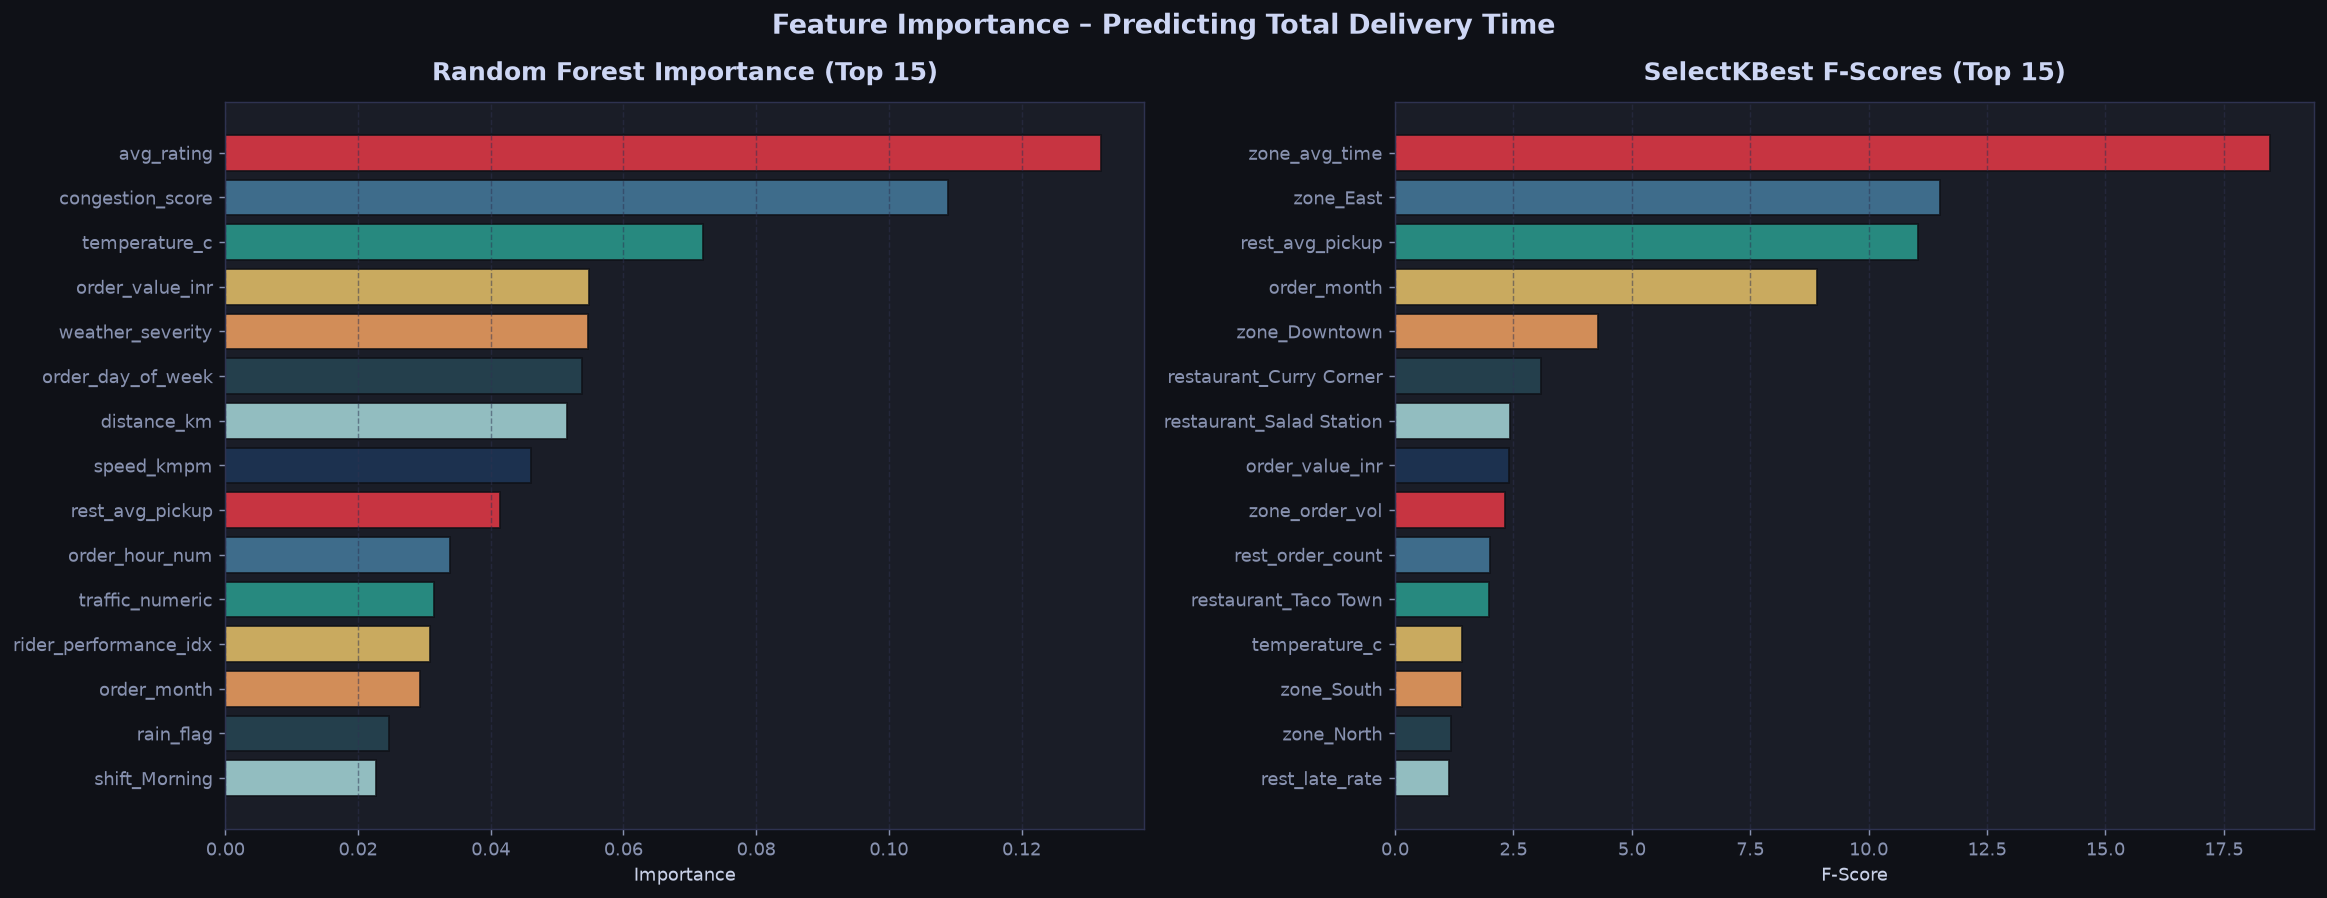

In [41]:
# Feature importance plot
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Feature Importance – Predicting Total Delivery Time', fontsize=15, fontweight='bold')

c_fi = [PALETTE[i % len(PALETTE)] for i in range(15)]
t15r  = rf_imp.head(15)
t15s  = skb_scores.head(15)

axes[0].barh(t15r.index[::-1], t15r.values[::-1], color=c_fi[::-1], edgecolor='#0F1117', alpha=0.85)
axes[0].set_xlabel('Importance')
axes[0].set_title('Random Forest Importance (Top 15)')
axes[0].grid(True, axis='x')

axes[1].barh(t15s.index[::-1], t15s.values[::-1], color=c_fi[::-1], edgecolor='#0F1117', alpha=0.85)
axes[1].set_xlabel('F-Score')
axes[1].set_title('SelectKBest F-Scores (Top 15)')
axes[1].grid(True, axis='x')

plt.tight_layout()
savefig('fig12_feature_importance')

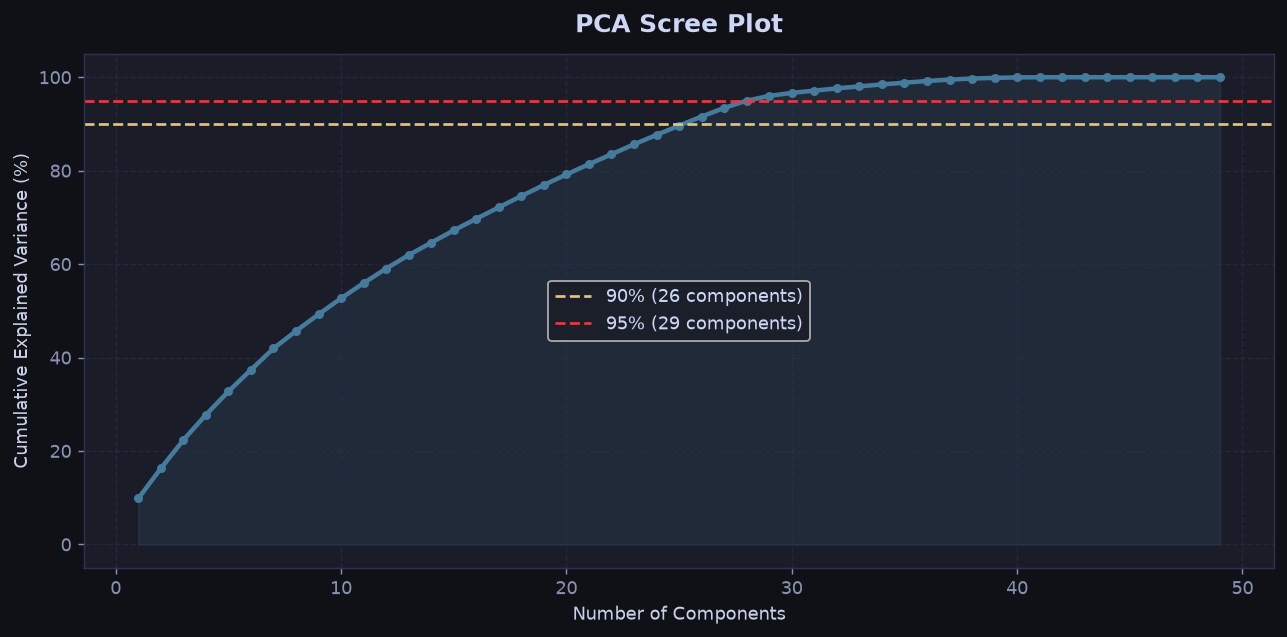

Total features: 49
Components for 90% variance: 26
Components for 95% variance: 29


In [42]:
# PCA
scaler = StandardScaler()
X_sc = scaler.fit_transform(X)
pca  = PCA(random_state=42)
pca.fit(X_sc)
cumvar = np.cumsum(pca.explained_variance_ratio_)
n90 = np.argmax(cumvar >= 0.90) + 1
n95 = np.argmax(cumvar >= 0.95) + 1

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, len(cumvar)+1), cumvar*100, color='#457B9D', lw=2.5, marker='o', ms=4)
ax.axhline(90, color='#E9C46A', ls='--', lw=1.5, label=f'90% ({n90} components)')
ax.axhline(95, color='#E63946', ls='--', lw=1.5, label=f'95% ({n95} components)')
ax.fill_between(range(1, len(cumvar)+1), cumvar*100, alpha=0.15, color='#457B9D')
ax.set_xlabel('Number of Components')
ax.set_ylabel('Cumulative Explained Variance (%)')
ax.set_title('PCA Scree Plot')
ax.legend()
ax.grid(True)
plt.tight_layout()
savefig('fig13_pca_scree')

print(f'Total features: {X.shape[1]}')
print(f'Components for 90% variance: {n90}')
print(f'Components for 95% variance: {n95}')

In [43]:
# Final feature set (consensus)
top_rf  = set(rf_imp.head(12).index)
top_skb = set(skb_scores.head(12).index)
selected = sorted(top_rf.union(top_skb))
print(f'Final selected features ({len(selected)}):')
for f in selected:
    rr = list(rf_imp.index).index(f)+1 if f in rf_imp.index else 'N/A'
    sr = list(skb_scores.index).index(f)+1 if f in skb_scores.index else 'N/A'
    print(f'  {f:45s} RF={rr}  F={sr}')

Final selected features (21):
  avg_rating                                    RF=1  F=24
  congestion_score                              RF=2  F=44
  distance_km                                   RF=7  F=39
  order_day_of_week                             RF=6  F=37
  order_hour_num                                RF=10  F=31
  order_month                                   RF=13  F=4
  order_value_inr                               RF=4  F=8
  rest_avg_pickup                               RF=9  F=3
  rest_order_count                              RF=23  F=10
  restaurant_Curry Corner                       RF=33  F=6
  restaurant_Salad Station                      RF=19  F=7
  restaurant_Taco Town                          RF=27  F=11
  rider_performance_idx                         RF=12  F=40
  speed_kmpm                                    RF=8  F=34
  temperature_c                                 RF=3  F=12
  traffic_numeric                               RF=11  F=36
  weather_severity     

In [44]:
# Save output files
df.to_csv('master_cleaned.csv', index=False)
df_encoded.to_csv('master_encoded.csv', index=False)
print(f'master_cleaned.csv saved: {df.shape}')
print(f'master_encoded.csv saved: {df_encoded.shape}')

master_cleaned.csv saved: (1065, 51)
master_encoded.csv saved: (1065, 69)


## 12. Summary & Insights

In [45]:
print('''
╔══════════════════════════════════════════════════════════════════╗
║   QuickBite Delivery – Round 2 Summary                         ║
╠══════════════════════════════════════════════════════════════════╣
║                                                                  ║
║  DATA QUALITY ISSUES RESOLVED (7 types)                         ║
║    1. Duplicate order IDs     → deduplicated                     ║
║    2. Missing timestamps      → rows dropped                     ║
║    3. Negative order values   → NaN then restaurant median       ║
║    4. Negative durations      → timestamps swapped               ║
║    5. Inconsistent zone names → mapped to 8 standard zones       ║
║    6. Missing distance        → zone-median imputation           ║
║    7. Missing weather data    → forward/backward fill            ║
║                                                                  ║
║  KEY INSIGHTS                                                    ║
║    Q1 Zone     → Airport & Suburbs: longest delivery times       ║
║    Q2 Traffic  → Very High traffic adds ~40-60% to total time    ║
║    Q3 Rain     → Heavy rain significantly increases delay        ║
║    Q4 Rest.    → Noodle House & Curry Corner slowest pickup      ║
║    Q5 Distance → r > 0.7 with total time; 3 min/km base rate    ║
║    Q6 Time     → Peak: 12-14h (lunch) and 18-21h (dinner)       ║
║                                                                  ║
║  FEATURES ENGINEERED (23)                                        ║
║    Temporal: hour, day, month, is_weekend, is_peak, time_of_day  ║
║    Traffic:  traffic_numeric, congestion_score, speed_kmpm       ║
║    Weather:  bad_weather, weather_severity                       ║
║    Rider:    rider_exp_score, rider_performance_idx              ║
║    Rest:     rest_avg_pickup, rest_order_count, rest_late_rate   ║
║    Zone:     zone_avg_time, zone_late_rate, zone_order_vol       ║
║    Target:   is_delayed (SLA = 45 min)                           ║
║                                                                  ║
║  FEATURE SELECTION (3 methods)                                   ║
║    SelectKBest (F-regression), Random Forest Importance, PCA     ║
║    Top drivers: congestion_score, distance_km, traffic_numeric,  ║
║                 zone_avg_time, rest_avg_pickup, weather_severity ║
║                                                                  ║
║  OUTPUT FILES                                                    ║
║    master_cleaned.csv  – cleaned merged dataset                  ║
║    master_encoded.csv  – encoded, ML-ready dataset               ║
╚══════════════════════════════════════════════════════════════════╝
''')


╔══════════════════════════════════════════════════════════════════╗
║   QuickBite Delivery – Round 2 Summary                         ║
╠══════════════════════════════════════════════════════════════════╣
║                                                                  ║
║  DATA QUALITY ISSUES RESOLVED (7 types)                         ║
║    1. Duplicate order IDs     → deduplicated                     ║
║    2. Missing timestamps      → rows dropped                     ║
║    3. Negative order values   → NaN then restaurant median       ║
║    4. Negative durations      → timestamps swapped               ║
║    5. Inconsistent zone names → mapped to 8 standard zones       ║
║    6. Missing distance        → zone-median imputation           ║
║    7. Missing weather data    → forward/backward fill            ║
║                                                                  ║
║  KEY INSIGHTS                                                    ║
║    Q1 Zone     → Airport & Suburbs